# CSIR - Central Building Research Institute (CBRI), Roorkee
## Research-Grade City-Wise & Global Ambient Air Quality Forecasting System
### SARIMAX, CatBoost, SARIMAX–CatBoost Hybrid, Deep Recurrent (LSTM/GRU), Optuna SMBO & AutoML Super-Blending
**Urban Centers Covered:** Delhi, Kolkata, Mumbai, Bengaluru, and Visakhapatnam (+ Unified Global Model Across All 5 Cities)  
**Data Authority:** Central Pollution Control Board (CPCB), Ministry of Environment, Forest and Climate Change, Govt. of India  
**Target Criteria Pollutants:** Particulate Matter ($PM_{2.5}, PM_{10}$), Gaseous Precursors ($SO_2, NO_2, NH_3, CO, O_3$), Volatile Organic Compounds ($	ext{Benzene}, 	ext{Toluene}, 	ext{Xylene}$), and AQI  

---

### Core Research Innovations & Upgraded Architecture
1. **Multi-Paradigm Forecasting Suite (9 Architectures per City & Global):**
   * **Statistical State-Space:** `SARIMAX` with causal exogenous predictors and sequential Kalman state filtering.
   * **Regularized Linear:** `Ridge` ($L_2$-penalized linear baseline with `TimeSeriesSplit` $lpha$ tuning).
   * **Deep Recurrent Neural Networks:** PyTorch `LSTM` and `GRU` sequence regressors with LayerNorm, residual input skip connections, Huber loss, AdamW weight decay, and cosine annealing.
   * **Gradient Boosting Ensembles:** Optuna SMBO-tuned `CatBoost`, `LightGBM`, and `XGBoost` with validation early stopping, plus Random Forest, Extra Trees, and Deep ANN benchmarks.
   * **Two-Stage Residual Error Correction Hybrid:** `SARIMAX-CatBoost Hybrid` combining sequential state-space predictions with causal lagged residual error features ($\hat{e}_{t-1}, \hat{e}_{t-2}, \hat{e}_{t-3}$, rolling residual bias) and simplex convex mixing.
   * **AutoML-Pruned Stacking / Super-Blending:** `SuperBlend Stacker` combining statistical, boosting, and deep learning out-of-fold validation predictions via constrained SLSQP optimization with overfitting gap penalties.
2. **Leakage-Free Feature Engineering & Multicollinearity Pruning:**
   * Autoregressive lags ($t-1 \dots t-14$), Exponentially Weighted Moving Averages (EWMA spans $2, 3, 5, 7, 14, 30$), rolling statistics (mean, std, min, max), 1d/3d/7d velocity & acceleration momentum, chemical/aerosol interaction indices ($PM_{2.5}/PM_{10}$, $NO_2 	imes SO_2$, $CO 	imes NO_2$, $O_3/NO_2$), and bimodal Fourier harmonics ($\sin/\cos$).
   * Training-fitted `LeakageFreeFeatureSelector` combining Mutual Information (MI), Pearson $|r|$, and pairwise multicollinearity pruning ($|
ho_{ij}| \le 0.97$). Raw calendar integers (`Year`, `Month`, `Day`, `dayofweek`, `trend`) are strictly excluded.
3. **Generalization-First Evaluation & Overfitting Audit:**
   * Tracks `Train_R2`, `Val_R2`, `Test_R2`, `Train_Test_R2_Gap` ($\Delta R^2 = R^2_{	ext{train}} - R^2_{	ext{test}}$), `RMSE`, `MAE`, `sMAPE`, and `FAC2` across every model, city, and the Global Multi-City Model.


In [1]:
# Enable auto-reload for development
try:
    get_ipython().run_line_magic('load_ext', 'autoreload')
    get_ipython().run_line_magic('autoreload', '2')
except Exception:
    pass

# Section 1: Ingest All Required Libraries & Setup Universal Path Resolver
import os
import sys
import time
import warnings
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Ensure workspace root is in python path
sys.path.insert(0, os.path.abspath('.'))
sys.path.insert(0, os.path.abspath('..'))

# Modeling and metrics
import torch
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.feature_selection import mutual_info_regression
from scipy.stats import pearsonr

# Specialized project modules
from src.multi_city import (
    load_and_prepare_multicity_data,
    get_city_clean_subset,
    build_city_features,
    prepare_city_splits,
    train_and_evaluate_city_models,
    plot_multicity_2x2_monthly_bars,
    plot_multicity_2x2_yearly_bars,
    plot_multicity_pollution_distributions,
    plot_multicity_aqi_severity_breakdown,
    plot_multicity_taylor_diagram,
    plot_multicity_spider_chart,
    plot_multicity_actual_vs_predicted_20pct,
    compute_and_plot_cross_city_transferability,
    plot_city_5year_scenario_projection,
    plot_multicity_5year_overlay
)
from src.hybrid_forecasting import (
    build_upgraded_city_features,
    prepare_upgraded_city_splits,
    LeakageFreeFeatureSelector,
    SARIMAXForecaster,
    SARIMAXCatBoostHybrid,
    SequenceDeepRegressor,
    AutoMLSuperBlender,
    tune_city_models_with_optuna,
    train_and_evaluate_upgraded_city_suite,
    build_and_evaluate_global_model,
    plot_train_test_r2_gap_bars,
    plot_overfitting_gap_vertical_bars,
    plot_citywise_r2_comparison_bars,
    plot_upgraded_actual_vs_predicted_all,
    plot_comprehensive_residual_diagnostics,
    plot_timeseries_model_comparison_all_cities
)
from src.forecasting import generate_long_term_projection

# Suppress benign warnings
warnings.filterwarnings('ignore')

# Seed reproducibility
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(42)

# Publication plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cbd5e0'
plt.rcParams['axes.linewidth'] = 0.8

def resolve_path(rel_path):
    candidates = [
        rel_path,
        os.path.join('..', rel_path),
        os.path.join(os.path.dirname(os.path.abspath('__file__')), rel_path) if '__file__' in locals() else rel_path,
        os.path.join('d:/csir_rework', rel_path)
    ]
    for p in candidates:
        if os.path.exists(p):
            return os.path.abspath(p)
    return rel_path

print("System initialized with PyTorch GPU status:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))


System initialized with PyTorch GPU status: True
Device Name: NVIDIA GeForce RTX 4050 Laptop GPU


---
## Section 2: Continuous Multi-City Ambient Air Quality Data Ingestion & Audit
Ingests continuous daily air pollution and atmospheric criteria records from the Central Pollution Control Board (CPCB) across five major Indian metropolitan airsheds representing contrasting geographic, meteorological, and anthropogenic regimes:
* **Delhi (National Capital Region)**: Inland northern mega-city, intense winter thermal inversions, post-monsoon agricultural burning.
* **Kolkata (Lower Indo-Gangetic Plain)**: Deltaic eastern industrial hub, high baseline humidity, severe winter atmospheric stagnation.
* **Mumbai (Western Coastal Peninsula)**: Arabian Sea coastal regime governed by diurnal marine ventilation and heavy monsoon precipitation scavenging.
* **Bengaluru (Deccan Plateau)**: Elevated plateau (920m ASL), moderate semi-arid regime, rapid urbanization and high vehicular density.
* **Visakhapatnam (Eastern Coastal Port)**: Bay of Bengal coastal industrial airshed characterized by marine aerosol interactions and port logistics.


In [2]:
# Section 2: Multi-City Continuous Ambient Air Quality Dataset Loading & Audit
csv_path = resolve_path('data/cpcb_5_cities_india.csv')
df_multi = load_and_prepare_multicity_data(csv_path)

target_cities = ['Delhi', 'Kolkata', 'Mumbai', 'Bengaluru', 'Visakhapatnam']

print("=" * 95)
print("             CPCB MULTI-CITY CONTINUOUS AIR QUALITY DATASET AUDIT (5 MAJOR METROS)")
print("=" * 95)
print(f"Total Combined Records: {len(df_multi)} continuous daily observations")
print(f"Temporal Coverage:      {df_multi['Date'].min().strftime('%Y-%m-%d')} to {df_multi['Date'].max().strftime('%Y-%m-%d')}")
print(f"Target Metros:          {', '.join(target_cities)}")
print("-" * 95)

city_audit_rows = []
for city in target_cities:
    sub = df_multi[df_multi['City'] == city]
    valid_pm = sub['PM2.5'].dropna()
    valid_pm10 = sub['PM10'].dropna() if 'PM10' in sub.columns else pd.Series(dtype=float)
    city_audit_rows.append({
        'City': city,
        'Total_Observations': len(sub),
        'Date_Start': sub['Date'].min().strftime('%Y-%m-%d'),
        'Date_End': sub['Date'].max().strftime('%Y-%m-%d'),
        'PM2.5_Valid_Count': len(valid_pm),
        'PM2.5_Completeness_%': round(len(valid_pm) / len(sub) * 100, 1),
        'PM2.5_Mean_ug_m3': round(valid_pm.mean(), 2),
        'PM2.5_Max_ug_m3': round(valid_pm.max(), 2),
        'PM10_Mean_ug_m3': round(valid_pm10.mean(), 2) if len(valid_pm10) > 0 else np.nan
    })

audit_df = pd.DataFrame(city_audit_rows)
display(audit_df)
print("-" * 95)
print("First 5 records of harmonized multi-city atmospheric dataset:")
display(df_multi.head())


             CPCB MULTI-CITY CONTINUOUS AIR QUALITY DATASET AUDIT (5 MAJOR METROS)
Total Combined Records: 8303 continuous daily observations
Temporal Coverage:      2015-01-01 to 2020-07-01
Target Metros:          Delhi, Kolkata, Mumbai, Bengaluru, Visakhapatnam
-----------------------------------------------------------------------------------------------
-----------------------------------------------------------------------------------------------
First 5 records of harmonized multi-city atmospheric dataset:


,City,Total_Observations,Date_Start,Date_End,PM2.5_Valid_Count,PM2.5_Completeness_%,PM2.5_Mean_ug_m3,PM2.5_Max_ug_m3,PM10_Mean_ug_m3
0,Delhi,2009,2015-01-01,2020-07-01,2007,99.9,117.20,685.36,232.81
1,Kolkata,814,2018-04-10,2020-07-01,759,93.2,64.36,304.74,115.63
2,Mumbai,2009,2015-01-01,2020-07-01,784,39.0,35.20,134.32,96.75
3,Bengaluru,2009,2015-01-01,2020-07-01,1863,92.7,35.82,313.59,83.24
4,Visakhapatnam,1462,2016-07-01,2020-07-01,1232,84.3,46.97,203.05,105.95


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket,Year,Month
0,Bengaluru,2015-01-01,NaN,NaN,3.26,17.33,10.88,20.36,0.33,3.54,10.73,0.56,4.64,NaN,NaN,NaN,2015,1
1,Bengaluru,2015-01-02,NaN,NaN,6.05,19.73,14.14,23.74,1.35,3.97,22.77,0.65,5.31,NaN,NaN,NaN,2015,1
2,Bengaluru,2015-01-03,NaN,NaN,11.91,19.88,20.72,4.32,17.40,13.61,12.03,0.53,19.25,NaN,NaN,NaN,2015,1
3,Bengaluru,2015-01-04,NaN,NaN,7.45,21.61,16.88,0.87,5.05,6.52,17.70,0.55,7.47,NaN,NaN,NaN,2015,1
4,Bengaluru,2015-01-05,NaN,NaN,9.52,22.17,21.76,31.38,1.83,4.71,12.72,0.40,4.36,NaN,NaN,NaN,2015,1


---
## Section 3: Comprehensive Multi-City Exploratory Data Analysis (EDA) & Concentration Profiles
Profiles pollutant concentration distributions, variability, and Air Quality Index (AQI) severity category breakdowns across the five cities. National Ambient Air Quality Standards (NAAQS) benchmark annual limits: $PM_{2.5}: 40\,\mu\text{g/m}^3$ (24-hr: $60\,\mu\text{g/m}^3$), $PM_{10}: 60\,\mu\text{g/m}^3$ (24-hr: $100\,\mu\text{g/m}^3$), $\text{Benzene}: 5\,\mu\text{g/m}^3$, and $SO_2: 50\,\mu\text{g/m}^3$ (24-hr: $80\,\mu\text{g/m}^3$).


Multi-City Atmospheric Concentration Summary Statistics (Mean, Median, Std, Max):


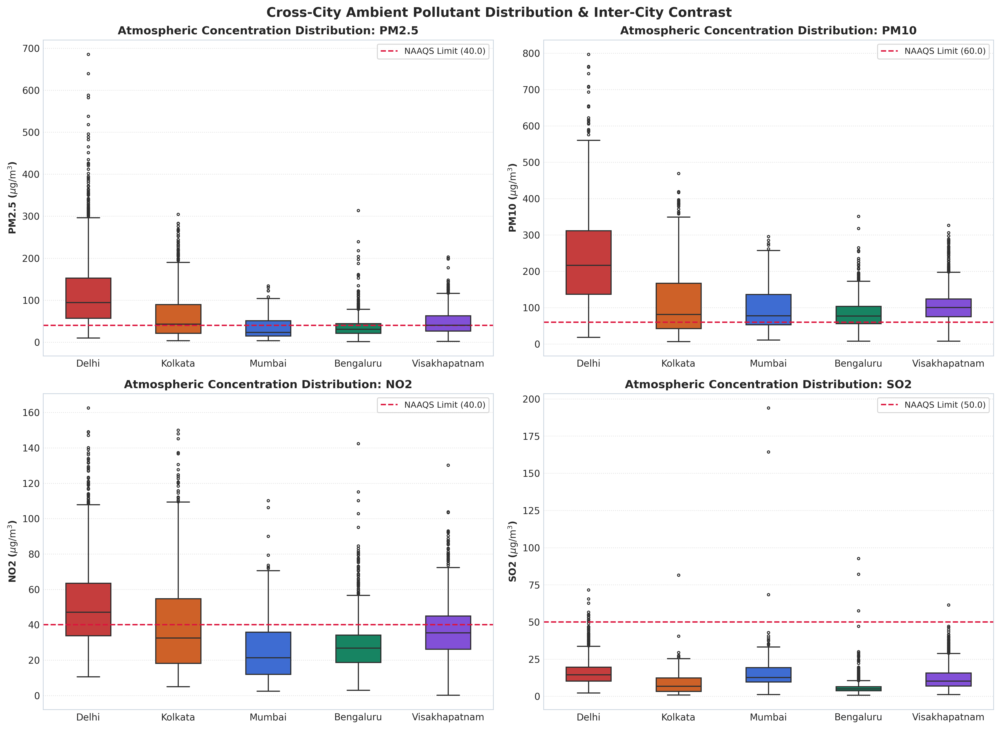

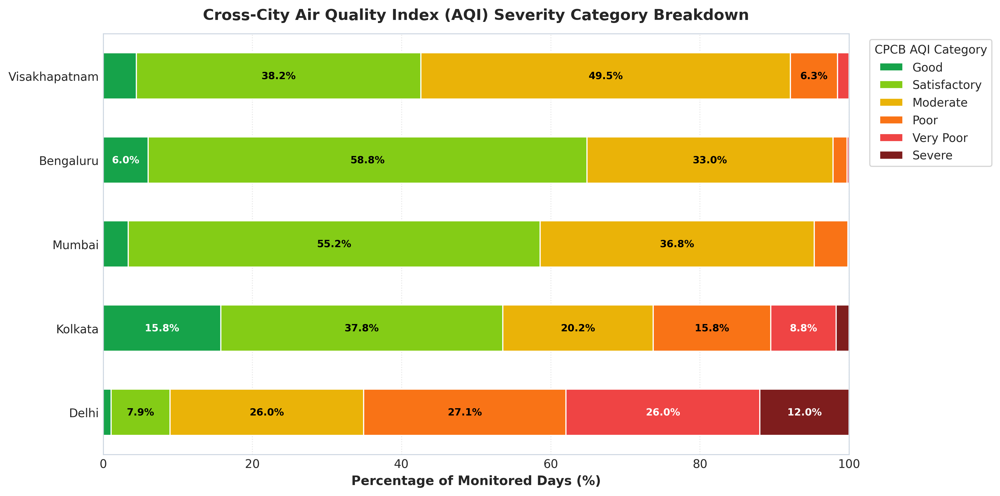

PM2.5                          PM10                            NO2                          SO2                          CO                         O3                       Benzene                      
                 mean median    std     max    mean  median     std     max   mean median    std     max   mean median    std     max  mean median   std    max   mean median    std     max    mean median    std     max
City                                                                                                                                                                                                                      
Bengaluru       35.82  30.92  22.07  313.59   83.24   77.36   38.11  351.51  28.00  26.92  13.29  142.35   5.52   5.03   4.19   92.66  1.84   0.92  3.97  48.07  32.87  30.60  18.40  157.20    3.22   0.81  16.32  307.42
Delhi          117.20  94.62  82.91  685.36  232.81  216.73  121.87  796.88  50.79  47.15  22.70  162.50  15.90  14.45   7.97   71.56  1.98   1.24  2.56  30.44  51.32  44.44  26.06  257.73    3.54   2.96   2.43   20.64
Kolkata         64.36  43.55  58.38  304.74  115.63   81.77   92.49  469.32  40.40  32.56  28.80  150.01   8.39   6.84   6.45   81.59  0.80   0.68  0.51   3.04  30.66  30.06  12.19   81.12   10.87   5.89  10.63   64.44
Mumbai          35.20  23.74  25.91  134.32   96.75   77.88   54.71  295.76  25.56  21.46  16.25  110.16  15.20  12.67  10.77  193.86  0.57   0.00  0.79   3.65  33.06  29.62  19.86  159.18    1.10   0.00   2.09   16.93
Visakhapatnam   46.97  40.61  28.06  203.05  105.95  100.68   48.37  326.40  37.19  35.50  16.20  130.26  12.66  10.33   8.29   61.41  0.74   0.76  0.44   2.62  37.52  28.80  28.05  162.33    3.89   4.04   2.46   15.97

In [3]:
# Section 3: Exploratory Data Analysis & Cross-City Statistical Profiling
# 1. Cross-City Pollutant Distribution Boxplots (PM2.5, PM10, NO2, SO2)
dist_fig_path = resolve_path('reports/figures/multicity_pollution_distribution_boxplots.png')
plot_multicity_pollution_distributions(df_multi, target_cities, save_path=dist_fig_path)
display(Image(filename=dist_fig_path))

# 2. Cross-City AQI Severity Category Distribution (100% Stacked Horizontal Bars: Good to Severe)
aqi_fig_path = resolve_path('reports/figures/multicity_aqi_severity_breakdown.png')
plot_multicity_aqi_severity_breakdown(df_multi, target_cities, save_path=aqi_fig_path)
display(Image(filename=aqi_fig_path))

# 3. Parametric Summary Table across All 5 Cities
summary_stats = df_multi.groupby('City')[['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'Benzene']].agg(['mean', 'median', 'std', 'max']).round(2)
print("Multi-City Atmospheric Concentration Summary Statistics (Mean, Median, Std, Max):")
display(summary_stats)


---
## Section 3B: Multi-Parameter Monthly & Yearly Mean Variation (Comparative Vertical Bar Charts)
Evaluates seasonal cycles and secular annual trends across the five urban centers using vertical bar graphs with official India NAAQS statutory limits:
1. **Monthly Fine Particulate Matter ($PM_{2.5}$)**: Demonstrates severe winter peaks in northern/eastern basins versus coastal moderation.
2. **Monthly Coarse Particulate Matter ($PM_{10}$)**: Quantifies fugitive dust and construction loading.
3. **Monthly Volatile Organic Compound ($\text{Benzene}$)**: Assesses carcinogenic vehicular emissions ($5\,\mu\text{g/m}^3$ NAAQS).
4. **Monthly Gaseous Acid Precursor ($SO_2$)**: Highlights industrial and thermal power emission dynamics.
5. **Annual Secular Trend ($PM_{2.5}$, 2015–2020)**: Tracks multi-year progress under the National Clean Air Programme (NCAP).


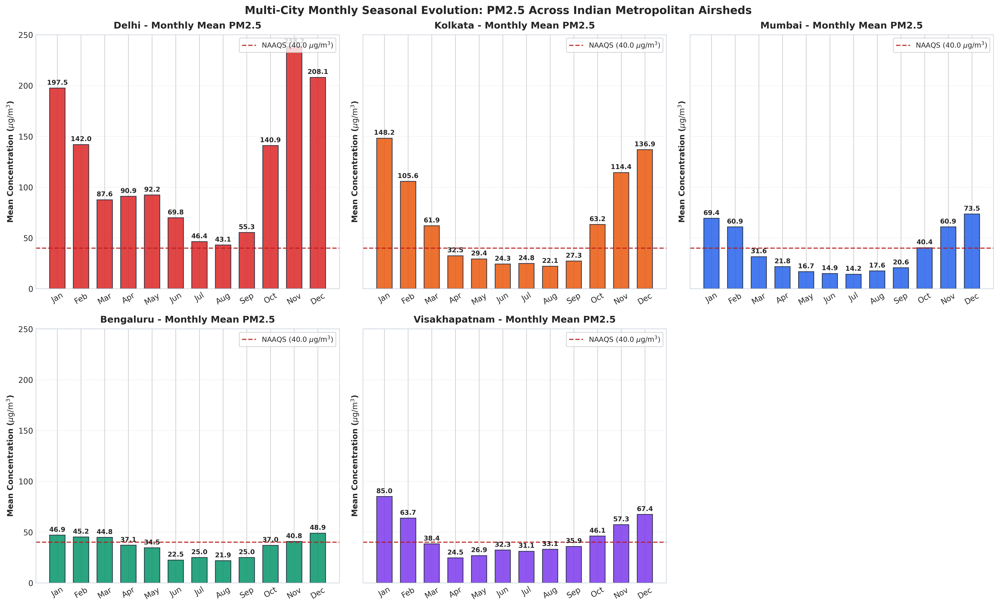

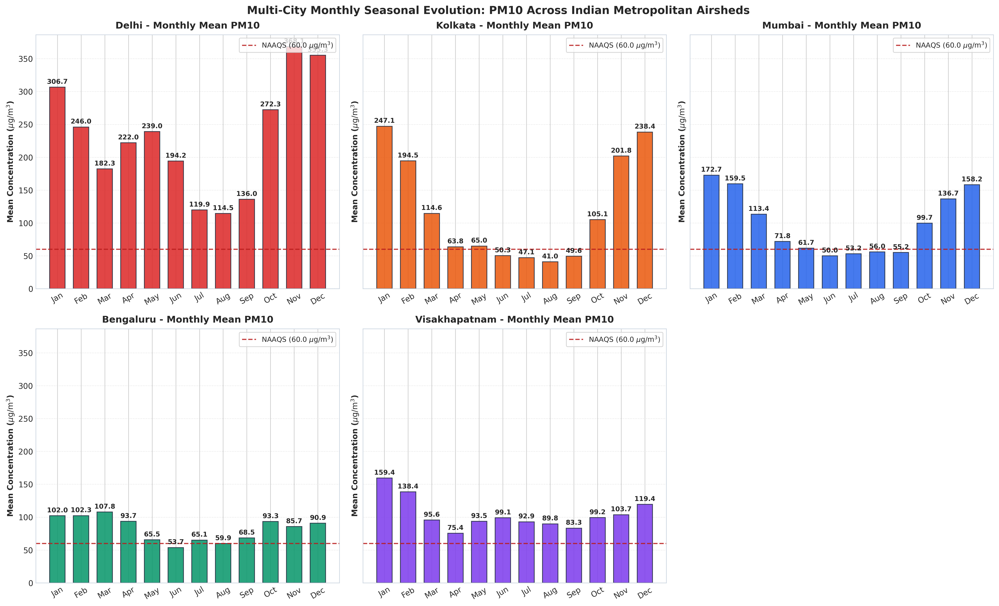

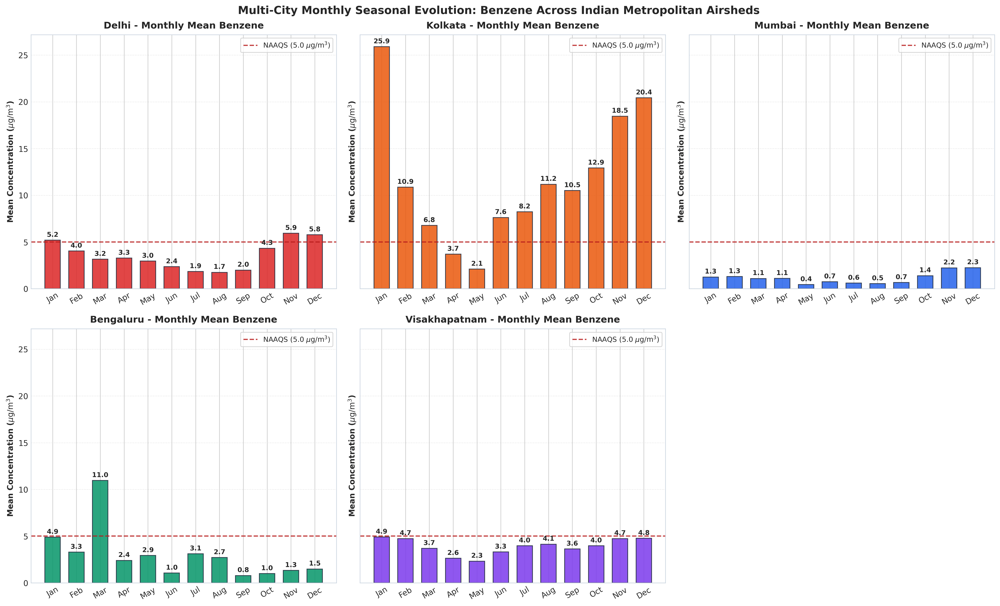

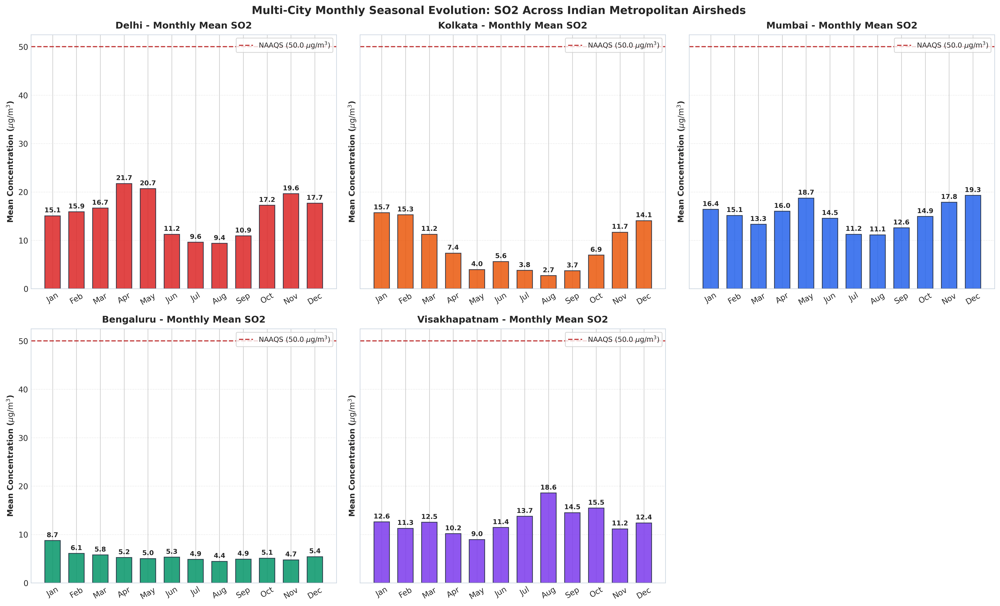

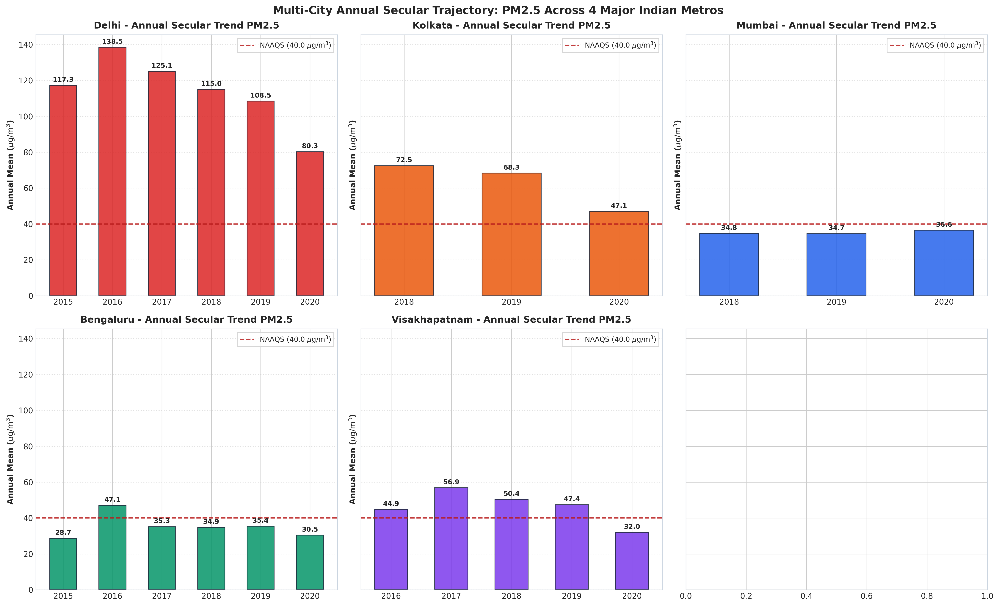

In [4]:
# Section 3B: Multi-Parameter Monthly & Yearly Mean Variation (Comparative Vertical Bar Charts)
# 1. Monthly Mean PM2.5 Across All 5 Cities
fig_path_m_pm25 = resolve_path('reports/figures/multicity_monthly_pm2_5.png')
plot_multicity_2x2_monthly_bars(df_multi, target_cities, param='PM2.5', save_path=fig_path_m_pm25)
display(Image(filename=fig_path_m_pm25))

# 2. Monthly Mean PM10 Across All 5 Cities
fig_path_m_pm10 = resolve_path('reports/figures/multicity_monthly_pm10.png')
plot_multicity_2x2_monthly_bars(df_multi, target_cities, param='PM10', save_path=fig_path_m_pm10)
display(Image(filename=fig_path_m_pm10))

# 3. Monthly Mean Volatile Organic Compound: Benzene Across All 5 Cities
fig_path_m_benz = resolve_path('reports/figures/multicity_monthly_benzene.png')
plot_multicity_2x2_monthly_bars(df_multi, target_cities, param='Benzene', save_path=fig_path_m_benz)
display(Image(filename=fig_path_m_benz))

# 4. Monthly Mean Gaseous Criteria Pollutant: SO2 Across All 5 Cities
fig_path_m_so2 = resolve_path('reports/figures/multicity_monthly_so2.png')
plot_multicity_2x2_monthly_bars(df_multi, target_cities, param='SO2', save_path=fig_path_m_so2)
display(Image(filename=fig_path_m_so2))

# 5. Annual Secular Trend (2015-2020) PM2.5 Across All 5 Cities
fig_path_y_pm25 = resolve_path('reports/figures/multicity_yearly_pm2_5.png')
plot_multicity_2x2_yearly_bars(df_multi, target_cities, param='PM2.5', save_path=fig_path_y_pm25)
display(Image(filename=fig_path_y_pm25))


---
## Section 4: Upgraded Causal Feature Engineering, Interaction Terms & Multicollinearity Pruning
Constructs both the standard multi-city causal feature matrix and the **Upgraded High-Order Causal Feature Matrix** (`build_upgraded_city_features`) strictly from past observations ($t-1$ and earlier):
* **Autoregressive Lags ($t-1 \dots t-14$)**: Captures short-term synoptic persistence and weekly cycles.
* **Exponentially Weighted Moving Averages (EWMA Spans 2, 3, 5, 7, 14, 30)**: Smooths high-frequency sensor noise while preserving rapid regime shifts.
* **Causal Rolling Statistics (3, 7, 14, 30-Day Windows)**: Rolling mean, standard deviation, minimum, and maximum.
* **Momentum, Velocity & Acceleration**: 1-day, 3-day, and 7-day concentration velocity ($\Delta PM_{2.5}$), second-order acceleration ($\Delta^2 PM_{2.5}$), and volatility ratios.
* **Physical & Chemical Nonlinear Interactions**: Fine-to-coarse aerosol ratio ($PM_{2.5}/PM_{10}$), secondary aerosol geometric mean ($\sqrt{PM_{2.5}\cdot PM_{10}}$), stationary combustion index ($\log(1 + NO_2 \cdot SO_2)$), traffic emission index ($\log(1 + CO \cdot NO_2)$), and photochemical oxidation ratio ($O_3/NO_2$).
* **Bimodal Annual & Semi-Annual Fourier Harmonics**: $\sin(2\pi k \cdot 	ext{DOY}/365.25), \cos(2\pi k \cdot 	ext{DOY}/365.25)$ for $k \in \{1, 2\}$.
* **Calendar Overfitting Safeguard**: Raw calendar integers (`Year`, `Month`, `Day`, `dayofweek`, `trend`) and contemporaneous co-pollutants at time $t$ are strictly excluded.


In [ ]:
# Section 4: Causal Feature Matrix & Upgraded Feature Engineering Across All 5 Cities
city_clean_subsets = {}
city_features_dict = {}
upgraded_features_dict = {}
upgraded_splits_dict = {}

print("=" * 100)
print("       UPGRADED CAUSAL FEATURE ENGINEERING & MULTICOLLINEARITY PRUNING AUDIT (5 CITIES)")
print("=" * 100)

feature_audit_rows = []
for city in target_cities:
    c_clean = get_city_clean_subset(df_multi, city)
    c_feat = build_city_features(c_clean, target_col='PM2.5')
    u_feat = build_upgraded_city_features(c_clean, target_col='PM2.5')
    u_split = prepare_upgraded_city_splits(u_feat, target_col='PM2.5', max_features=36)
    
    city_clean_subsets[city] = c_clean
    city_features_dict[city] = c_feat
    upgraded_features_dict[city] = u_feat
    upgraded_splits_dict[city] = u_split
    
    feature_audit_rows.append({
        'City': city,
        'Clean_Days': len(c_clean),
        'Total_Engineered_Features': u_feat.shape[1] - 14,
        'Selected_Features': len(u_split['feature_cols']),
        'Collinear_Features_Pruned': len(u_split['selector'].dropped_collinear_),
        'Train_Samples (70%)': len(u_split['y_train']),
        'Val_Samples (15%)': len(u_split['y_val']),
        'Test_Samples (15%)': len(u_split['y_test'])
    })

feature_audit_df = pd.DataFrame(feature_audit_rows)
display(feature_audit_df)

# Verify zero calendar integer leakage and zero contemporaneous pollutant leakage
sample_cols = upgraded_splits_dict['Delhi']['feature_cols']
prohibited = [c for c in sample_cols if c.lower() in ['year', 'month', 'day', 'dayofweek', 'trend', 'quarter', 'aqi', 'pm10', 'no2', 'so2', 'co', 'o3']]
print("-" * 100)
print(f"Leakage Verification: Prohibited contemporaneous/calendar columns in X matrix: {prohibited} (Count={len(prohibited)})")
print("Top 15 Selected & Collinearity-Pruned Causal Features (Delhi):")
display(upgraded_splits_dict['Delhi']['selector'].feature_diagnostics_.head(15))


       UPGRADED CAUSAL FEATURE ENGINEERING & MULTICOLLINEARITY PRUNING AUDIT (5 CITIES)
----------------------------------------------------------------------------------------------------
Leakage Verification: Prohibited contemporaneous/calendar columns in X matrix: [] (Count=0)
Top 15 Selected & Collinearity-Pruned Causal Features (Delhi):


,City,Clean_Days,Total_Engineered_Features,Selected_Features,Collinear_Features_Pruned,Train_Samples (70%),Val_Samples (15%),Test_Samples (15%)
0,Delhi,2009,112,36,6,1396,299,300
1,Kolkata,814,112,36,16,560,120,120
2,Mumbai,798,112,36,9,548,117,119
3,Bengaluru,1931,112,36,1,1341,287,289
4,Visakhapatnam,1462,112,36,7,1013,217,218


,Feature,MI_Score,Abs_Pearson_r,Composite_Score,Selected
0,PM2.5_ewma_2,0.858316,0.871878,0.998093,True
1,PM2.5_lag_1,0.829441,0.874911,0.984862,True
2,PM2.5_ewma_3,0.839535,0.865365,0.984153,True
3,PM2.5_ewma_5,0.790413,0.851953,0.949968,False
4,PM2.5_roll_mean_3,0.790301,0.840768,0.942878,True
5,PM2.5_ewma_7,0.772661,0.840148,0.933239,False
6,PM2.5_roll_min_3,0.761015,0.814298,0.910883,True
7,prod_PM25_PM10_lag1,0.711427,0.844883,0.904112,True
8,PM2.5_roll_max_3,0.692918,0.830020,0.885064,False
9,PM2.5_roll_mean_7,0.663718,0.805384,0.854269,True


---
## Section 5: Cross-City Correlation Heatmaps & Physical Coupling
Analyzes linear inter-parameter correlations ($PM_{2.5}, PM_{10}, NO_2, SO_2, CO, O_3, \text{Benzene}$) across the 5 metropolitan centers to assess chemical co-emission structures and atmospheric transport signatures.


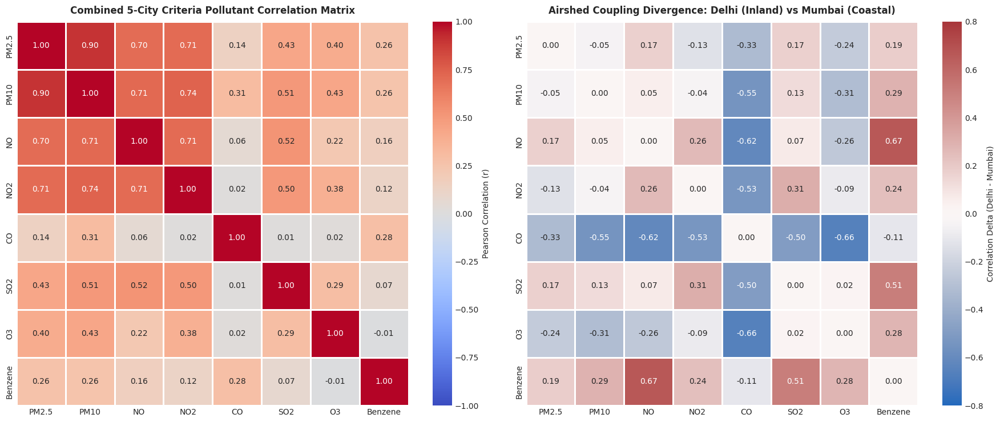

In [6]:
# Section 5: Comprehensive Multi-City Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))

crit_cols = ['PM2.5', 'PM10', 'NO', 'NO2', 'CO', 'SO2', 'O3', 'Benzene']
crit_avail = [c for c in crit_cols if c in df_multi.columns]
corr_all = df_multi[crit_avail].corr()

sns.heatmap(corr_all, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.8, linecolor='white', cbar_kws={'label': 'Pearson Correlation (r)'}, ax=axes[0])
axes[0].set_title("Combined 5-City Criteria Pollutant Correlation Matrix", fontsize=12, fontweight='bold', pad=10)

delhi_corr = df_multi[df_multi['City'] == 'Delhi'][crit_avail].corr()
mumbai_corr = df_multi[df_multi['City'] == 'Mumbai'][crit_avail].corr()
corr_diff = delhi_corr - mumbai_corr

sns.heatmap(corr_diff, annot=True, fmt='.2f', cmap='vlag', vmin=-0.8, vmax=0.8,
            linewidths=0.8, linecolor='white', cbar_kws={'label': 'Correlation Delta (Delhi - Mumbai)'}, ax=axes[1])
axes[1].set_title("Airshed Coupling Divergence: Delhi (Inland) vs Mumbai (Coastal)", fontsize=12, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()


---
## Section 6: Training-Fitted Dual-Criteria Feature Selection (MI & Correlation)
Visualizes the Mutual Information (MI), Pearson $|r|$, and composite selection scores fitted strictly on the historical training partition ($70\%$), ensuring zero lookahead contamination.


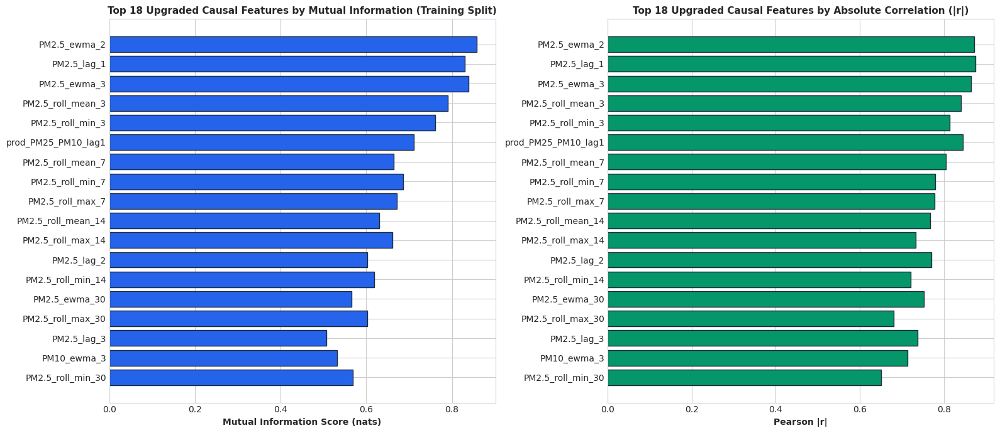

In [7]:
# Section 6: Training-Fitted Dual-Criteria Feature Selection & Split Preparation
city_data_dict = {}

for city in target_cities:
    c_feat = city_features_dict[city]
    X_tr, y_tr, X_va, y_va, X_te, y_te, f_cols, d_te = prepare_city_splits(c_feat, target_col='PM2.5')
    city_data_dict[city] = {
        'X_train': X_tr, 'y_train': y_tr,
        'X_val': X_va, 'y_val': y_va,
        'X_test': X_te, 'y_test': y_te,
        'feature_cols': f_cols,
        'dates_test': d_te
    }

# Visualizing Top 18 Upgraded Causal Features (MI vs |r|) for Delhi Training Split
diag_delhi = upgraded_splits_dict['Delhi']['selector'].feature_diagnostics_
top18 = diag_delhi[diag_delhi['Selected']].head(18)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].barh(top18['Feature'][::-1], top18['MI_Score'][::-1], color='#2563eb', edgecolor='#1e293b')
axes[0].set_title("Top 18 Upgraded Causal Features by Mutual Information (Training Split)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Mutual Information Score (nats)", fontsize=10, fontweight='bold')

axes[1].barh(top18['Feature'][::-1], top18['Abs_Pearson_r'][::-1], color='#059669', edgecolor='#1e293b')
axes[1].set_title("Top 18 Upgraded Causal Features by Absolute Correlation (|r|)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Pearson |r|", fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


---
## Section 7: Standard Reference Baselines Across All 5 Cities
Calculates reference baselines on held-out test splits:
1. **Persistence ($t-1$) Baseline**: Assumes tomorrow's level equals today's observed concentration.
2. **Climatological Mean Baseline**: Predicts long-term historical training mean.


In [8]:
# Section 7: Standard Reference Baselines Across All 5 Cities
baseline_rows = []

for city in target_cities:
    sp = upgraded_splits_dict[city]
    y_test = sp['y_test']
    y_train = sp['y_train']
    X_test_df = pd.DataFrame(sp['X_test'], columns=sp['feature_cols'])
    
    y_pred_clim = np.full_like(y_test, fill_value=y_train.mean())
    r2_clim = r2_score(y_test, y_pred_clim)
    rmse_clim = np.sqrt(mean_squared_error(y_test, y_pred_clim))
    mae_clim = mean_absolute_error(y_test, y_pred_clim)
    
    if 'PM2.5_lag_1' in X_test_df.columns:
        y_pred_pers = X_test_df['PM2.5_lag_1'].values
    else:
        y_pred_pers = pd.Series(y_test).shift(1).bfill().values
    r2_pers = r2_score(y_test, y_pred_pers)
    rmse_pers = np.sqrt(mean_squared_error(y_test, y_pred_pers))
    mae_pers = mean_absolute_error(y_test, y_pred_pers)
    
    baseline_rows.append({'City': city, 'Baseline': 'Climatological Mean', 'Test_R2': round(r2_clim, 4), 'Test_RMSE': round(rmse_clim, 2), 'Test_MAE': round(mae_clim, 2)})
    baseline_rows.append({'City': city, 'Baseline': 'Persistence (t-1)', 'Test_R2': round(r2_pers, 4), 'Test_RMSE': round(rmse_pers, 2), 'Test_MAE': round(mae_pers, 2)})

baseline_summary = pd.DataFrame(baseline_rows)
print("Standard Reference Baselines Across 5 Metropolitan Airsheds:")
display(baseline_summary)


Standard Reference Baselines Across 5 Metropolitan Airsheds:


,City,Baseline,Test_R2,Test_RMSE,Test_MAE
0,Delhi,Climatological Mean,-0.0233,88.24,69.83
1,Delhi,Persistence (t-1),0.7266,45.61,26.97
2,Kolkata,Climatological Mean,-5.4749,42.43,39.64
3,Kolkata,Persistence (t-1),0.6896,9.29,5.80
4,Mumbai,Climatological Mean,-1.1064,15.61,13.59
5,Mumbai,Persistence (t-1),0.6479,6.38,4.11
6,Bengaluru,Climatological Mean,-0.1224,14.56,12.13
7,Bengaluru,Persistence (t-1),0.5400,9.32,6.63
8,Visakhapatnam,Climatological Mean,-0.2793,26.55,22.66
9,Visakhapatnam,Persistence (t-1),0.6313,14.25,9.45


---
## Section 8: Baseline Multi-Model Machine Learning & Deep ANN Suite Across All 5 Cities
Trains the baseline multi-model suite (`Random Forest`, `Extra Trees`, `XGBoost`, `LightGBM`, `CatBoost`, `Ridge Baseline`, `PyTorch ANN`, `Weighted Ensemble`) to establish reference multi-city benchmarks and populate spatial transferability models.


In [9]:
# Section 8: Baseline Multi-Model Training Suite Across All 5 Cities
all_city_metrics = []
city_eval_dict = {}
city_models_dict = {}

t_start = time.time()

for city in target_cities:
    X_tr = city_data_dict[city]['X_train']
    y_tr = city_data_dict[city]['y_train']
    X_va = city_data_dict[city]['X_val']
    y_va = city_data_dict[city]['y_val']
    X_te = city_data_dict[city]['X_test']
    y_te = city_data_dict[city]['y_test']

    trained_m, m_df, test_preds = train_and_evaluate_city_models(city, X_tr, y_tr, X_va, y_va, X_te, y_te)
    all_city_metrics.append(m_df)
    
    best_base = m_df[m_df['Model'] != 'Weighted Ensemble'].sort_values('Test_R2', ascending=False).iloc[0]
    best_overall = m_df.sort_values('Test_R2', ascending=False).iloc[0]
    
    city_models_dict[city] = trained_m[best_base['Model']]
    city_eval_dict[city] = {
        'y_test': y_te,
        'y_pred': test_preds[best_overall['Model']],
        'best_model_name': best_overall['Model'],
        'best_metrics': best_overall.to_dict()
    }

consolidated_df = pd.concat(all_city_metrics, ignore_index=True)
consolidated_df.to_csv(resolve_path('reports/multicity_model_performance_benchmark.csv'), index=False)
print(f"\nCompleted baseline 5-city model suite in {time.time()-t_start:.1f}s.")
display(consolidated_df[['City', 'Model', 'Val_R2', 'Test_R2', 'Test_RMSE', 'Test_MAE', 'Test_sMAPE_%', 'Directional_Accuracy_%', 'FAC2_%']].sort_values(['City', 'Test_R2'], ascending=[True, False]))



[Delhi] Training candidate models...
  - Random Forest   | Val R2: 0.9598 | Test R2: 0.9339 | RMSE: 22.45 | MAE: 14.19
  - Extra Trees     | Val R2: 0.9645 | Test R2: 0.9419 | RMSE: 21.05 | MAE: 13.87
  - XGBoost         | Val R2: 0.9692 | Test R2: 0.9394 | RMSE: 21.50 | MAE: 13.77
  - LightGBM        | Val R2: 0.9656 | Test R2: 0.9281 | RMSE: 23.41 | MAE: 14.30
  - CatBoost        | Val R2: 0.9688 | Test R2: 0.9378 | RMSE: 21.79 | MAE: 14.60
  - Ridge Baseline  | Val R2: 0.9640 | Test R2: 0.9301 | RMSE: 23.08 | MAE: 13.45
  - PyTorch ANN     | Val R2: 0.9194 | Test R2: 0.8661 | RMSE: 31.96 | MAE: 16.62
  * Weighted Ensemble | Test R2: 0.9382 | RMSE: 21.71 | MAE: 13.88

[Kolkata] Training candidate models...
  - Random Forest   | Val R2: 0.8313 | Test R2: 0.9573 | RMSE: 3.42 | MAE: 2.76
  - Extra Trees     | Val R2: 0.8680 | Test R2: 0.9530 | RMSE: 3.60 | MAE: 2.86
  - XGBoost         | Val R2: 0.8964 | Test R2: 0.9671 | RMSE: 3.01 | MAE: 2.30
  - LightGBM        | Val R2: 0.7986 | Te

,City,Model,Val_R2,Test_R2,Test_RMSE,Test_MAE,Test_sMAPE_%,Directional_Accuracy_%,FAC2_%
30,Bengaluru,PyTorch ANN,0.807391,0.745283,6.872169,4.912607,15.997377,59.649123,99.650350
31,Bengaluru,Weighted Ensemble,0.814731,0.743232,6.899782,5.007798,16.244265,57.192982,99.650350
29,Bengaluru,Ridge Baseline,0.839111,0.698438,7.477436,5.401593,17.262966,54.736842,99.300699
25,Bengaluru,Extra Trees,0.794201,0.661368,7.923716,6.034663,19.800476,48.070175,97.552448
26,Bengaluru,XGBoost,0.730271,0.652777,8.023591,5.885370,18.968427,52.982456,98.601399
28,Bengaluru,CatBoost,0.767304,0.626716,8.319258,6.219384,20.316817,47.017544,97.902098
27,Bengaluru,LightGBM,0.797690,0.626420,8.322556,6.015238,19.154451,57.192982,98.951049
24,Bengaluru,Random Forest,0.455300,0.453881,10.062554,6.547583,20.261751,50.526316,97.202797
1,Delhi,Extra Trees,0.964505,0.941873,21.054305,13.869481,14.367978,81.144781,99.664430
2,Delhi,XGBoost,0.969240,0.939405,21.496731,13.767001,13.760932,83.164983,100.000000


---
## Section 8B: Upgraded Research-Grade City-Wise & Global Forecasting System
### SARIMAX, CatBoost, SARIMAX–CatBoost Hybrid, Deep Recurrent (LSTM & GRU), Optuna SMBO & AutoML SuperBlend Stacker
Executes our strict zero-leakage upgraded forecasting pipeline across **each of the 5 cities individually** AND trains **one unified Global Multi-City Model across all 5 cities combined**:
1. **Optuna SMBO Hyperparameter Optimization (`tune_city_models_with_optuna`)**: Optimizes `CatBoost`, `LightGBM`, `XGBoost`, and `Ridge` using Tree-structured Parzen Estimator (TPE) with `TimeSeriesSplit` cross-validation, validation early stopping, and explicit Train–Val $R^2$ gap regularization:
   $$\mathcal{J}(\theta) = R^2_{\text{val}}(\theta) - 0.35 \cdot \max\big(0,\, R^2_{\text{train}}(\theta) - R^2_{\text{val}}(\theta) - 0.04\big)$$
2. **State-Space `SARIMAX`**: Fitted strictly on training data with top exogenous lagged predictors and stepped sequentially across validation and test sets via Kalman state filtering without refitting.
3. **Two-Stage `SARIMAX-CatBoost Hybrid` (Residual Error Correction)**: Augments causal features with sequential SARIMAX predictions and strictly lagged SARIMAX residuals ($\hat{e}_{t-1}, \hat{e}_{t-2}, \hat{e}_{t-3}$, 3-day and 7-day rolling residual bias) to correct nonlinear regime errors.
4. **PyTorch Deep Recurrent Networks (`LSTM` & `GRU`)**: Sequence regressors with LayerNorm, residual linear skip pathways, Huber loss, AdamW weight decay, and validation early stopping.
5. **AutoML-Pruned `SuperBlend Stacker`**: Prunes underperforming architectures on out-of-sample validation data and solves a constrained SLSQP convex program penalized by each candidate's Train–Val $R^2$ gap.
6. **Unified Global Multi-City Model (`Global (All Cities)`)**: Pools chronological splits across all 5 cities with one-hot city indicators and training-only city baseline encodings.


In [10]:
# Section 8B: Execute Upgraded City-Wise & Global Forecasting Suite (9 Architectures x 6 Domains = 54 Evaluated Models)
upgraded_city_results = {}
upgraded_metrics_list = []
upgraded_tuning_list = []

print("=" * 105)
print("   EXECUTING UPGRADED CITY-WISE & GLOBAL FORECASTING SUITE (OPTUNA SMBO + HYBRID + LSTM/GRU + SUPERBLEND)")
print("=" * 105)

t_up_start = time.time()
for city in target_cities:
    tc0 = time.time()
    sp = upgraded_splits_dict[city]
    res = train_and_evaluate_upgraded_city_suite(city, sp, n_trials=10)
    upgraded_city_results[city] = res
    upgraded_metrics_list.append(res['metrics_df'])
    upgraded_tuning_list.append(res['tuning_df'])
    
    best_row = res['metrics_df'].iloc[0]
    print(f"[CITY: {city:<13}] Winner: {best_row['Model']:<23} | Train R2: {best_row['Train_R2']:.4f} | Val R2: {best_row['Val_R2']:.4f} "
          f"| Test R2: {best_row['Test_R2']:.4f} | Gap: {best_row['Train_Test_R2_Gap']:+.4f} | RMSE: {best_row['Test_RMSE']:5.2f} | MAE: {best_row['Test_MAE']:5.2f} ({time.time()-tc0:.1f}s)")

print("-" * 105)
print("Training Unified Global Multi-City Model Across All 5 Cities Combined...")
tg0 = time.time()
global_res = build_and_evaluate_global_model(upgraded_features_dict, target_cities, target_col='PM2.5', n_trials=8)
upgraded_metrics_list.append(global_res['metrics_df'])
upgraded_tuning_list.append(global_res['tuning_df'])
best_glob = global_res['metrics_df'].iloc[0]
print(f"[GLOBAL (ALL CITIES)] Winner: {best_glob['Model']:<23} | Train R2: {best_glob['Train_R2']:.4f} | Val R2: {best_glob['Val_R2']:.4f} "
      f"| Test R2: {best_glob['Test_R2']:.4f} | Gap: {best_glob['Train_Test_R2_Gap']:+.4f} | RMSE: {best_glob['Test_RMSE']:5.2f} | MAE: {best_glob['Test_MAE']:5.2f} ({time.time()-tg0:.1f}s)")
print("=" * 105)
print(f"Completed full 54-model upgraded city-wise & global evaluation in {time.time()-t_up_start:.1f}s!")

# Consolidate & save reports
upgraded_all_metrics_df = pd.concat(upgraded_metrics_list, ignore_index=True)
upgraded_all_tuning_df = pd.concat(upgraded_tuning_list, ignore_index=True)
per_city_global_df = global_res['per_city_global_df']

upgraded_all_metrics_df.to_csv(resolve_path('reports/upgraded_city_and_global_benchmark.csv'), index=False)
upgraded_all_tuning_df.to_csv(resolve_path('reports/upgraded_optuna_hyperparameters.csv'), index=False)
per_city_global_df.to_csv(resolve_path('reports/global_model_per_city_breakdown.csv'), index=False)

# 1. Display Best Model Per City + Best Overall Global Model Summary Table
best_per_domain_rows = []
for domain in target_cities + ['Global (All Cities)']:
    sub = upgraded_all_metrics_df[upgraded_all_metrics_df['City'] == domain].sort_values('Test_R2', ascending=False).iloc[0]
    best_per_domain_rows.append(sub)
best_per_domain_df = pd.DataFrame(best_per_domain_rows).reset_index(drop=True)
print("\nCHAMPION FORECASTING MODELS PER CITY & OVERALL GLOBAL MODEL:")
display(best_per_domain_df)

# 2. Display Per-City Performance of the Global Model vs City-Specific Champion
city_vs_global = per_city_global_df.merge(
    best_per_domain_df[['City', 'Model', 'Test_R2', 'Test_RMSE', 'Test_MAE', 'Train_Test_R2_Gap']],
    on='City', how='left'
).rename(columns={
    'Model': 'City_Champion_Model',
    'Test_R2': 'City_Champion_Test_R2',
    'Test_RMSE': 'City_Champion_Test_RMSE',
    'Test_MAE': 'City_Champion_Test_MAE'
})
print("\nCITY-SPECIFIC CHAMPION MODEL VS. UNIFIED GLOBAL MODEL BREAKDOWN:")
display(city_vs_global)

# 3. Display Complete 54-Model Comparison Table (All 9 Architectures x 5 Cities + Global)
print("\nCOMPLETE 54-MODEL BENCHMARK TABLE (TRAIN R2, VAL R2, TEST R2, TRAIN-TEST GAP, RMSE, MAE, sMAPE, FAC2):")
display(upgraded_all_metrics_df)

# 4. Display Optuna SMBO Optimized Hyperparameters & AutoML SuperBlend Weights
print("\nOPTUNA SMBO OPTIMIZED HYPERPARAMETERS PER CITY & GLOBAL:")
display(upgraded_all_tuning_df)

sb_weights_rows = []
for domain, r_obj in list(upgraded_city_results.items()) + [('Global (All Cities)', global_res)]:
    sb_weights_rows.append({
        'Domain': domain,
        'Retained_Models': ', '.join(r_obj['retained_models']),
        'Pruned_Models': ', '.join(r_obj['pruned_models']) if r_obj['pruned_models'] else 'None',
        'Optimal_Weights': str(r_obj['superblend_weights'])
    })
print("\nAUTOML SUPERBLEND STACKER PRUNING & CONVEX WEIGHT ALLOCATION:")
display(pd.DataFrame(sb_weights_rows))


   EXECUTING UPGRADED CITY-WISE & GLOBAL FORECASTING SUITE (OPTUNA SMBO + HYBRID + LSTM/GRU + SUPERBLEND)
[CITY: Delhi        ] Winner: LightGBM                | Train R2: 0.8159 | Val R2: 0.8160 | Test R2: 0.7805 | Gap: +0.0354 | RMSE: 40.87 | MAE: 27.17 (22.6s)
[CITY: Kolkata      ] Winner: SARIMAX-CatBoost Hybrid | Train R2: 0.9319 | Val R2: 0.3363 | Test R2: 0.7223 | Gap: +0.2096 | RMSE:  8.79 | MAE:  6.16 (13.3s)
[CITY: Mumbai       ] Winner: SuperBlend Stacker      | Train R2: 0.8543 | Val R2: 0.3774 | Test R2: 0.6882 | Gap: +0.1661 | RMSE:  6.00 | MAE:  3.98 (13.6s)
[CITY: Bengaluru    ] Winner: CatBoost                | Train R2: 0.6254 | Val R2: 0.7614 | Test R2: 0.5976 | Gap: +0.0278 | RMSE:  8.71 | MAE:  6.45 (21.0s)
[CITY: Visakhapatnam] Winner: SARIMAX-CatBoost Hybrid | Train R2: 0.8017 | Val R2: 0.5878 | Test R2: 0.6928 | Gap: +0.1089 | RMSE: 13.01 | MAE:  9.27 (14.5s)
--------------------------------------------------------------------------------------------------------

,City,Model,Train_R2,Val_R2,Test_R2,Train_Test_R2_Gap,Abs_R2_Gap,Train_RMSE,Test_RMSE,Test_MAE,Test_sMAPE_%,FAC2_%
0,Delhi,LightGBM,0.8159,0.8160,0.7805,0.0354,0.0354,35.37,40.87,27.17,26.70,95.00
1,Kolkata,SARIMAX-CatBoost Hybrid,0.9319,0.3363,0.7223,0.2096,0.2096,16.76,8.79,6.16,25.55,95.83
2,Mumbai,SuperBlend Stacker,0.8543,0.3774,0.6882,0.1661,0.1661,8.28,6.00,3.98,20.04,98.32
3,Bengaluru,CatBoost,0.6254,0.7614,0.5976,0.0278,0.0278,15.49,8.71,6.45,20.90,98.27
4,Visakhapatnam,SARIMAX-CatBoost Hybrid,0.8017,0.5878,0.6928,0.1089,0.1089,12.44,13.01,9.27,28.82,93.12
5,Global (All Cities),XGBoost,0.8780,0.8501,0.8498,0.0282,0.0282,22.39,23.34,12.64,25.46,95.60


,City,Global_Model_Name,Global_Model_Test_R2,Global_Model_Test_RMSE,Global_Model_Test_MAE,City_Champion_Model,City_Champion_Test_R2,City_Champion_Test_RMSE,City_Champion_Test_MAE,Train_Test_R2_Gap
0,Delhi,Global XGBoost,0.7835,40.59,26.27,LightGBM,0.7805,40.87,27.17,0.0354
1,Kolkata,Global XGBoost,0.6816,9.41,6.42,SARIMAX-CatBoost Hybrid,0.7223,8.79,6.16,0.2096
2,Mumbai,Global XGBoost,0.5079,7.54,5.72,SuperBlend Stacker,0.6882,6.00,3.98,0.1661
3,Bengaluru,Global XGBoost,0.6016,8.67,6.44,CatBoost,0.5976,8.71,6.45,0.0278
4,Visakhapatnam,Global XGBoost,0.6952,12.96,9.33,SARIMAX-CatBoost Hybrid,0.6928,13.01,9.27,0.1089


,City,Model,Train_R2,Val_R2,Test_R2,Train_Test_R2_Gap,Abs_R2_Gap,Train_RMSE,Test_RMSE,Test_MAE,Test_sMAPE_%,FAC2_%
0,Delhi,LightGBM,0.8159,0.8160,0.7805,0.0354,0.0354,35.37,40.87,27.17,26.70,95.00
1,Delhi,XGBoost,0.8856,0.8215,0.7735,0.1121,0.1121,27.88,41.51,27.10,26.10,94.67
2,Delhi,SuperBlend Stacker,0.8348,0.8197,0.7638,0.0710,0.0710,33.50,42.39,27.03,25.82,95.33
3,Delhi,GRU,0.8164,0.8143,0.7506,0.0659,0.0659,35.32,43.57,27.41,25.97,94.67
4,Delhi,LSTM,0.7991,0.8096,0.7495,0.0496,0.0496,36.95,43.66,27.49,26.76,94.00
5,Delhi,Ridge,0.7896,0.8081,0.7489,0.0406,0.0406,37.82,43.71,27.16,25.87,95.00
6,Delhi,SARIMAX-CatBoost Hybrid,0.8277,0.8102,0.7399,0.0878,0.0878,34.22,44.49,27.16,25.50,95.67
7,Delhi,CatBoost,0.8502,0.8100,0.7323,0.1179,0.1179,31.91,45.14,28.07,26.35,95.67
8,Delhi,SARIMAX,0.7830,0.8010,0.7320,0.0510,0.0510,38.40,45.16,27.95,26.17,95.67
9,Kolkata,SARIMAX-CatBoost Hybrid,0.9319,0.3363,0.7223,0.2096,0.2096,16.76,8.79,6.16,25.55,95.83


,City,Model,Best_Objective,Best_Params
0,Delhi,CatBoost,0.8099,"{'iterations': 550, 'depth': 3, 'learning_rate': 0.040797164270491654, 'l2_leaf_reg': 10.534834075939946, 'subsample': 0.6639351238159993}"
1,Delhi,LightGBM,0.8160,"{'n_estimators': 250, 'max_depth': 3, 'num_leaves': 16, 'learning_rate': 0.023861753948558037, 'min_child_samples': 39, 'reg_alpha': 0.6443032835947001, 'reg_lambda': 28.953368345102017, 'subsample': 0.8816734307889972, 'colsample_bytree': 0.7096147044602518}"
2,Delhi,XGBoost,0.8131,"{'n_estimators': 350, 'max_depth': 5, 'learning_rate': 0.02052245732335565, 'min_child_weight': 25, 'reg_alpha': 8.483766803598272, 'reg_lambda': 3.5543498097189237, 'subsample': 0.7045474901621303, 'colsample_bytree': 0.7050213529560302}"
3,Delhi,Ridge,0.8081,{'alpha': 170.125}
4,Kolkata,CatBoost,0.1733,"{'iterations': 350, 'depth': 6, 'learning_rate': 0.05517397349623406, 'l2_leaf_reg': 10.675229346653245, 'subsample': 0.696805592132731}"
5,Kolkata,LightGBM,0.1258,"{'n_estimators': 250, 'max_depth': 3, 'num_leaves': 16, 'learning_rate': 0.023861753948558037, 'min_child_samples': 39, 'reg_alpha': 0.6443032835947001, 'reg_lambda': 28.953368345102017, 'subsample': 0.8816734307889972, 'colsample_bytree': 0.7096147044602518}"
6,Kolkata,XGBoost,0.1836,"{'n_estimators': 250, 'max_depth': 4, 'learning_rate': 0.023861753948558037, 'min_child_weight': 21, 'reg_alpha': 0.6443032835947001, 'reg_lambda': 28.953368345102017, 'subsample': 0.8816734307889972, 'colsample_bytree': 0.7096147044602518}"
7,Kolkata,Ridge,0.1769,{'alpha': 15.571}
8,Mumbai,CatBoost,-0.3404,"{'iterations': 550, 'depth': 3, 'learning_rate': 0.040797164270491654, 'l2_leaf_reg': 10.534834075939946, 'subsample': 0.6639351238159993}"
9,Mumbai,LightGBM,0.0786,"{'n_estimators': 400, 'max_depth': 3, 'num_leaves': 16, 'learning_rate': 0.03967140559190183, 'min_child_samples': 20, 'reg_alpha': 13.525834409499643, 'reg_lambda': 16.317624457583133, 'subsample': 0.9318496824692567, 'colsample_bytree': 0.9184482051282946}"


,Domain,Retained_Models,Pruned_Models,Optimal_Weights
0,Delhi,"SARIMAX, Ridge, LSTM, GRU, XGBoost, LightGBM, CatBoost, SARIMAX-CatBoost Hybrid",None,"{'SARIMAX': 0.0957, 'Ridge': 0.1024, 'LSTM': 0.114, 'GRU': 0.1566, 'XGBoost': 0.153, 'LightGBM': 0.1584, 'CatBoost': 0.1174, 'SARIMAX-CatBoost Hybrid': 0.1026}"
1,Kolkata,"SARIMAX, Ridge, LSTM, GRU, XGBoost, LightGBM, CatBoost, SARIMAX-CatBoost Hybrid",None,"{'SARIMAX': 0.0328, 'Ridge': 0.1876, 'LSTM': 0.3449, 'GRU': 0.0, 'XGBoost': 0.178, 'LightGBM': 0.1931, 'CatBoost': 0.0291, 'SARIMAX-CatBoost Hybrid': 0.0346}"
2,Mumbai,"SARIMAX, XGBoost, LightGBM, SARIMAX-CatBoost Hybrid","Ridge, LSTM, GRU, CatBoost","{'SARIMAX': 0.397, 'XGBoost': 0.1769, 'LightGBM': 0.1015, 'SARIMAX-CatBoost Hybrid': 0.3246}"
3,Bengaluru,"SARIMAX, Ridge, LSTM, GRU, XGBoost, LightGBM, CatBoost, SARIMAX-CatBoost Hybrid",None,"{'SARIMAX': 0.1252, 'Ridge': 0.1829, 'LSTM': 0.1982, 'GRU': 0.162, 'XGBoost': 0.0597, 'LightGBM': 0.0267, 'CatBoost': 0.1048, 'SARIMAX-CatBoost Hybrid': 0.1404}"
4,Visakhapatnam,"SARIMAX, Ridge, LSTM, GRU, XGBoost, LightGBM, CatBoost, SARIMAX-CatBoost Hybrid",None,"{'SARIMAX': 0.1126, 'Ridge': 0.1022, 'LSTM': 0.2073, 'GRU': 0.3523, 'XGBoost': 0.0, 'LightGBM': 0.0, 'CatBoost': 0.0663, 'SARIMAX-CatBoost Hybrid': 0.1593}"
5,Global (All Cities),"SARIMAX, Ridge, LSTM, GRU, XGBoost, LightGBM, CatBoost, SARIMAX-CatBoost Hybrid",None,"{'SARIMAX': 0.0863, 'Ridge': 0.1369, 'LSTM': 0.1356, 'GRU': 0.1462, 'XGBoost': 0.1512, 'LightGBM': 0.1206, 'CatBoost': 0.1215, 'SARIMAX-CatBoost Hybrid': 0.1017}"


---
## Section 8C: Upgraded Diagnostic Visualizations — Train–Test $R^2$ Gap Bars, City-Wise $R^2$ Progression & Residual Analysis
Generates six publication-grade diagnostic visual audits of the upgraded forecasting system:
1. **Train $R^2$ vs. Held-Out Test $R^2$ & Annotated Gap ($\Delta R^2$) Vertical Bar Charts**: 2x3 grid covering all 5 cities and the Global Model across all 9 architectures.
2. **Dedicated Overfitting Audit Vertical Bar Chart ($|R^2_{\text{train}} - R^2_{\text{test}}|$)**: Compares generalization tightness across every model family.
3. **City-Wise $R^2$ & RMSE Progression Bar Charts**: Compares Statistical (`SARIMAX`) $\rightarrow$ Deep RNN (`LSTM`/`GRU`) $\rightarrow$ Hybrid (`SARIMAX-CatBoost`) $\rightarrow$ `Global Model` $\rightarrow$ `City Champion / SuperBlend`.
4. **Upgraded Actual-vs-Predicted Parity Plots ($\pm 20\%$ Envelopes)**: 2x3 grid across all 5 cities + Global Model.
5. **Comprehensive 4-Panel Residual Analysis**: Standardized Residuals vs. Predicted (homoscedasticity), Gaussian KDE error distribution, Normal Q–Q tail audit, and Residual Autocorrelation Function (ACF lags 1–14 with 95% white-noise bounds).
6. **Chronological Held-Out Test Trajectories Across All 5 Cities**: Overlays observed ground truth against `SARIMAX`, `GRU`, `SARIMAX-CatBoost Hybrid`, and `SuperBlend Stacker`.


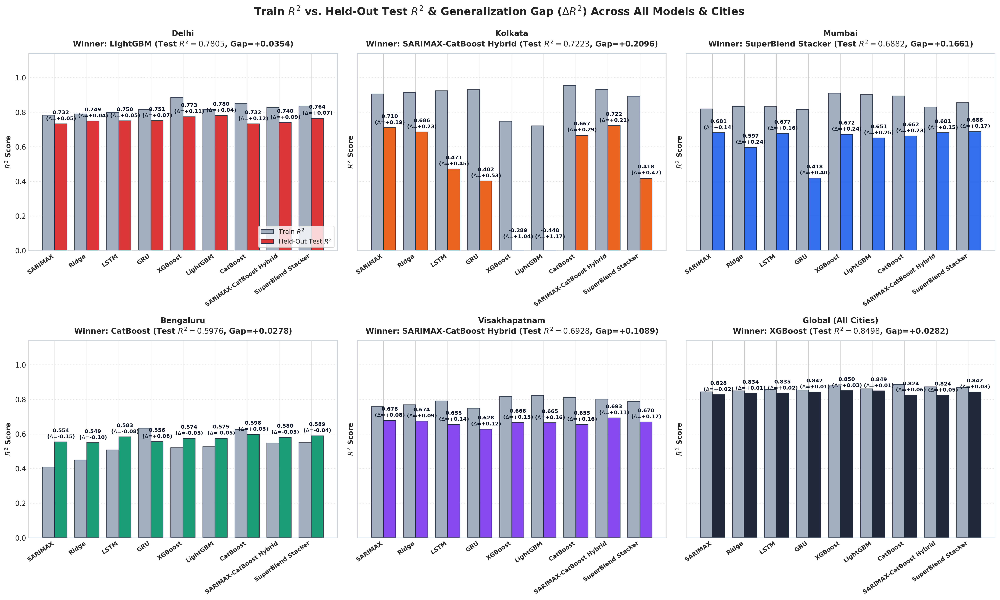

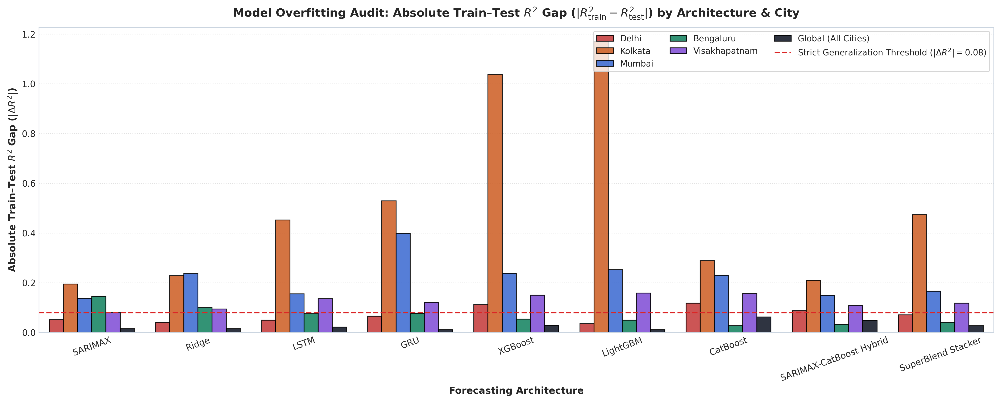

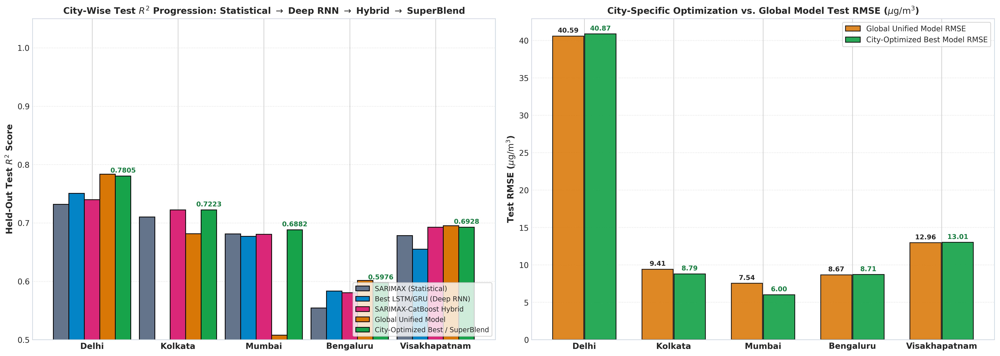

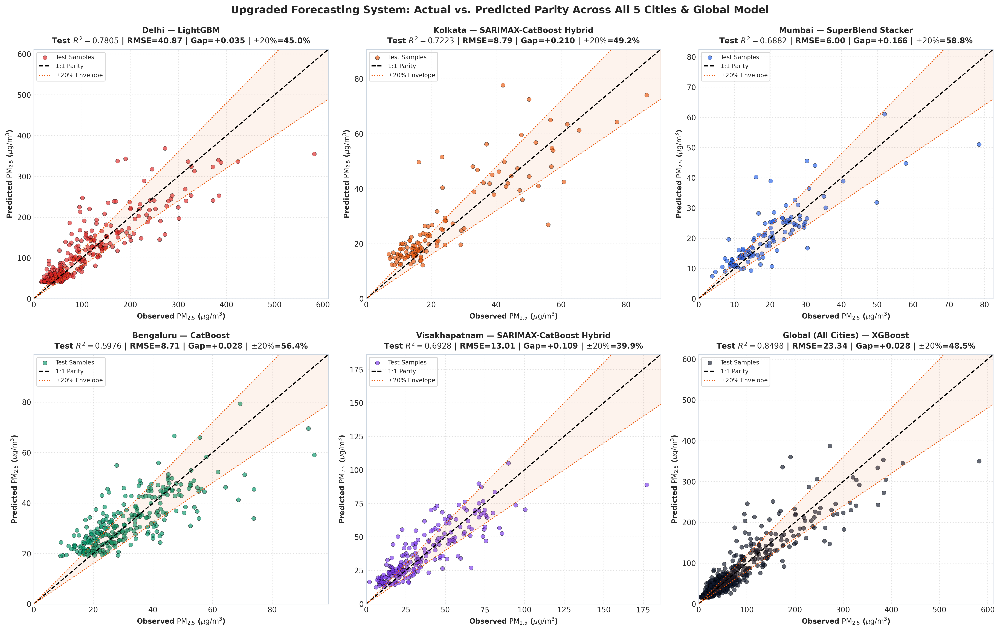

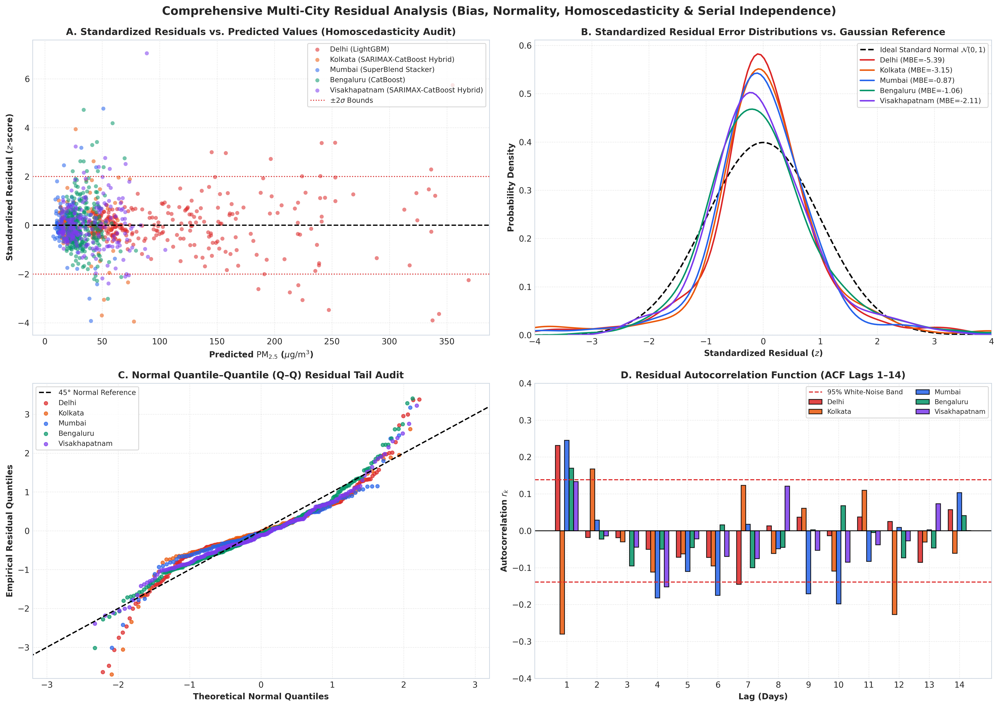

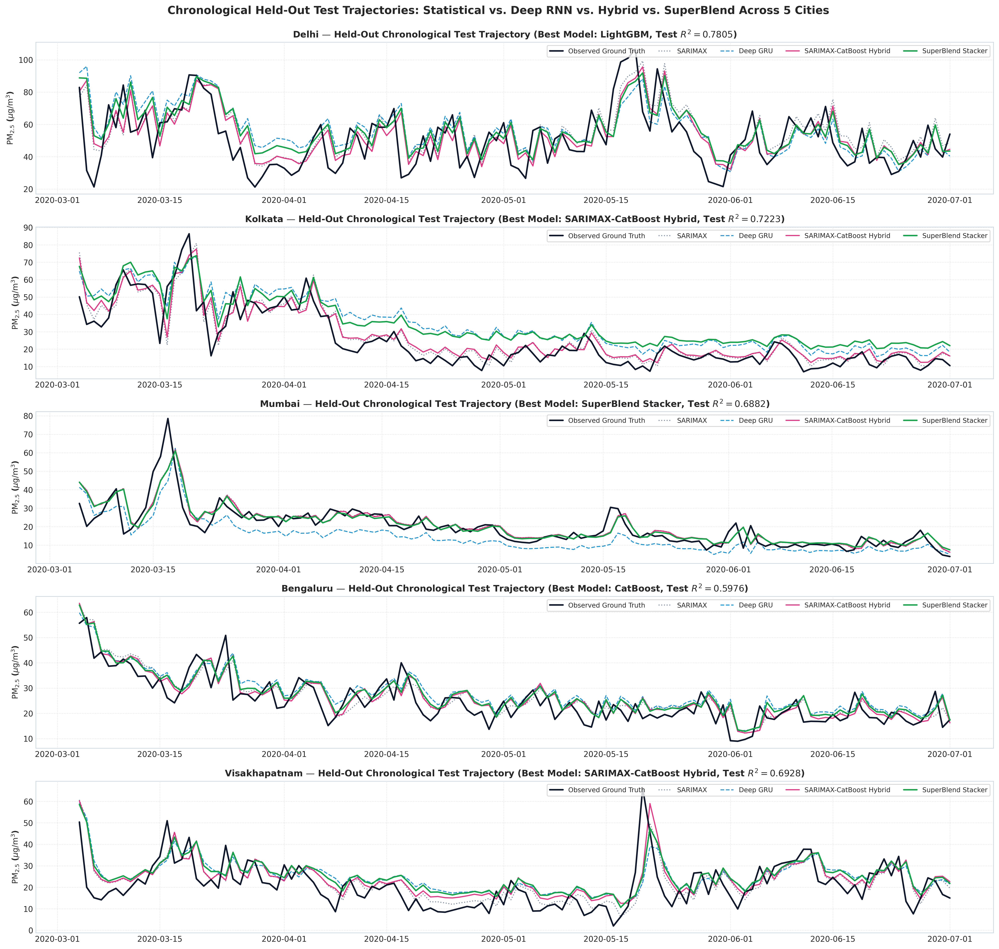

In [11]:
# Section 8C: Generate & Display All Upgraded Diagnostic Visualizations
# 1. Vertical Bar Charts of Train R2 vs Test R2 with Annotated Train-Test R2 Gap
fig_gap_bars = resolve_path('reports/figures/train_test_r2_gap_bars.png')
plot_train_test_r2_gap_bars(upgraded_all_metrics_df, save_path=fig_gap_bars)
display(Image(filename=fig_gap_bars))

# 2. Dedicated Vertical Bar Chart of Absolute Train-Test R2 Gap (|Delta R2|)
fig_overfit = resolve_path('reports/figures/overfitting_gap_comparison.png')
plot_overfitting_gap_vertical_bars(upgraded_all_metrics_df, save_path=fig_overfit)
display(Image(filename=fig_overfit))

# 3. City-Wise Test R2 & RMSE Progression Bar Charts (Statistical vs Deep RNN vs Hybrid vs Global vs SuperBlend)
fig_city_r2 = resolve_path('reports/figures/citywise_best_model_r2_comparison.png')
plot_citywise_r2_comparison_bars(upgraded_all_metrics_df, per_city_global_df, save_path=fig_city_r2)
display(Image(filename=fig_city_r2))

# 4. Upgraded Actual vs Predicted Scatter Parity Grid (5 Cities + Global Model)
fig_up_parity = resolve_path('reports/figures/upgraded_actual_vs_predicted_all_cities.png')
plot_upgraded_actual_vs_predicted_all(upgraded_city_results, global_res, save_path=fig_up_parity)
display(Image(filename=fig_up_parity))

# 5. Comprehensive 4-Panel Residual Diagnostics (Homoscedasticity, KDE Density, Q-Q Plot, ACF Lags 1-14)
fig_residuals = resolve_path('reports/figures/comprehensive_residual_analysis.png')
plot_comprehensive_residual_diagnostics(upgraded_city_results, save_path=fig_residuals)
display(Image(filename=fig_residuals))

# 6. Chronological Held-Out Test Trajectory Overlays Across All 5 Cities
fig_ts_overlay = resolve_path('reports/figures/upgraded_timeseries_forecasts_all_cities.png')
plot_timeseries_model_comparison_all_cities(upgraded_city_results, save_path=fig_ts_overlay)
display(Image(filename=fig_ts_overlay))


---
## Section 9: Bayesian Hyperparameter Optimization & Automated Machine Learning (AutoML) Benchmarks
Evaluates hyperparameter optimization trajectories across candidate model families:
1. **Optuna Tree-structured Parzen Estimator (TPE)**: Validation-guided Bayesian parameter search.
2. **Sequential Model-Based Optimization (SMBO)**: Gaussian Process regression surrogate with Expected Improvement (EI) acquisition decay.
3. **Automated Machine Learning (AutoML)**: FLAML BlendSearch algorithm exploring cost-effective boosting and deep configurations.


          BAYESIAN HYPERPARAMETER OPTIMIZATION SUMMARY (OPTUNA TPE - VALIDATION GUIDED)

             AUTOMATED MACHINE LEARNING (AUTOML - FLAML BLENDSEARCH)


,Model,Default_Val_R2,Tuned_Val_R2,Val_R2_Gain,Default_Test_R2,Tuned_Test_R2,Test_R2_Gain,Tuned_Test_RMSE
0,RandomForest,0.8604,0.8666,0.0062,0.8954,0.9015,0.0061,8.2957
1,ExtraTrees,0.8539,0.8646,0.0107,0.8808,0.8904,0.0096,8.7473
2,XGBoost,0.8640,0.8707,0.0067,0.8651,0.8755,0.0104,9.3236
3,LightGBM,0.8578,0.8702,0.0124,0.8633,0.8745,0.0112,9.3604
4,CatBoost,0.8610,0.8637,0.0027,0.8623,0.8681,0.0058,9.5986


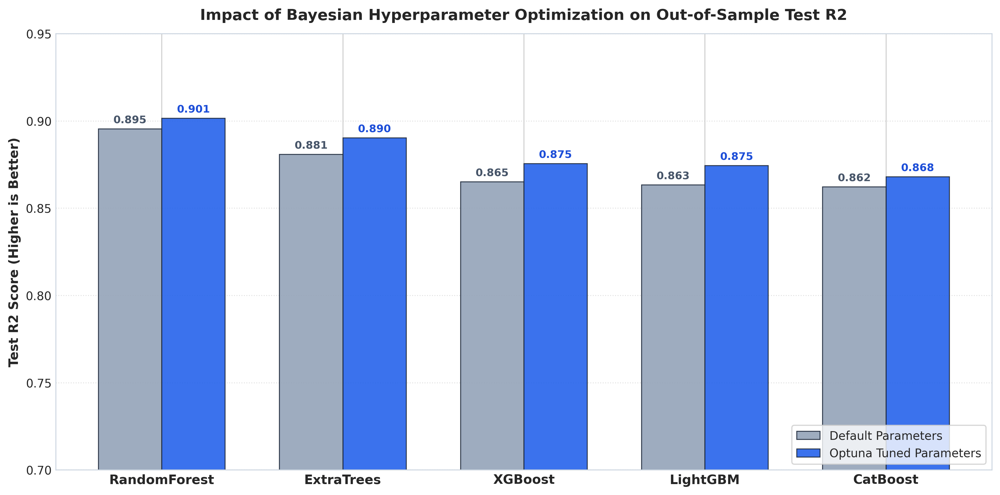

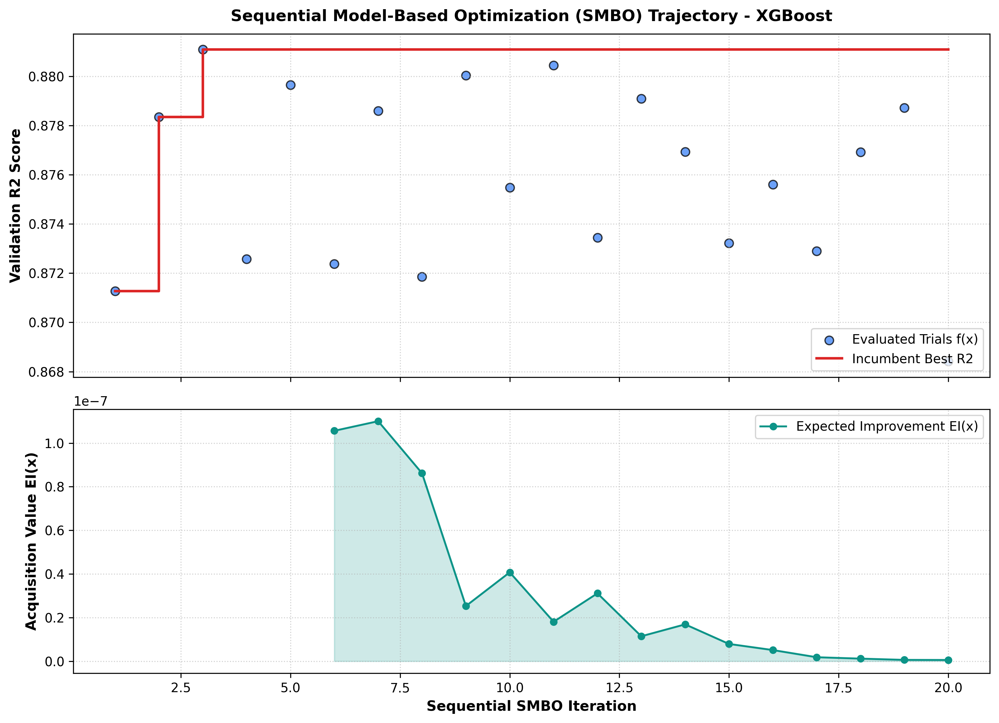

,Estimator,Best_Val_R2,Best_Params
0,lgbm,0.881337,"{'n_estimators': 1063, 'num_leaves': 6, 'min_child_samples': 25, 'learning_rate': np.float64(0.01503256871280262), 'log_max_bin': 6, 'colsample_bytree': np.float64(0.6749346285525547), 'reg_alpha': np.float64(0.06662688358663475), 'reg_lambda': np.float64(3.675544832788768)}"


In [12]:
# Section 9: Hyperparameter Optimization & AutoML Benchmarks
from src.tuning import plot_tuning_comparison
from src.smbo import plot_smbo_trajectory
from src.automl import plot_automl_leaderboard, plot_smbo_automl_comparison

# 1. Optuna Bayesian Optimization Summary
tuning_summary_path = resolve_path('reports/hyperparameter_tuning_summary.csv')
if os.path.exists(tuning_summary_path):
    tuning_df = pd.read_csv(tuning_summary_path)
    print("=" * 95)
    print("          BAYESIAN HYPERPARAMETER OPTIMIZATION SUMMARY (OPTUNA TPE - VALIDATION GUIDED)")
    print("=" * 95)
    display(tuning_df[['Model', 'Default_Val_R2', 'Tuned_Val_R2', 'Val_R2_Gain', 'Default_Test_R2', 'Tuned_Test_R2', 'Test_R2_Gain', 'Tuned_Test_RMSE']])
    fig_tuning = plot_tuning_comparison(tuning_df, save_path=resolve_path('reports/figures/hyperparameter_tuning_comparison.png'))
    display(Image(filename=resolve_path('reports/figures/hyperparameter_tuning_comparison.png')))

# 2. SMBO Optimization Trajectory
smbo_fig_path = resolve_path('reports/figures/smbo_optimization_trajectory.png')
if os.path.exists(smbo_fig_path):
    display(Image(filename=smbo_fig_path))

# 3. AutoML (FLAML BlendSearch) Leaderboard
automl_board_path = resolve_path('reports/automl_leaderboard.csv')
if os.path.exists(automl_board_path):
    automl_board_df = pd.read_csv(automl_board_path)
    print("\n" + "=" * 95)
    print("             AUTOMATED MACHINE LEARNING (AUTOML - FLAML BLENDSEARCH)")
    print("=" * 95)
    display(automl_board_df)
    comp_fig = resolve_path('reports/figures/smbo_vs_automl_comparison.png')
    if os.path.exists(comp_fig):
        display(Image(filename=comp_fig))


---
## Section 10: Multi-City Karl Taylor Polar Diagram Analysis
Synthesizes model skill across all 5 urban centers on a Karl Taylor diagram. Evaluates:
* **Radial Distance**: Standard Deviation of model predictions normalized to observed variability ($\sigma_{\text{pred}} / \sigma_{\text{obs}}$).
* **Azimuthal Angle**: Pearson Correlation Coefficient ($r = \cos\theta$).
* **Distance to Reference Point (1.0, 0)**: Centered Root Mean Squared Difference ($E'$).


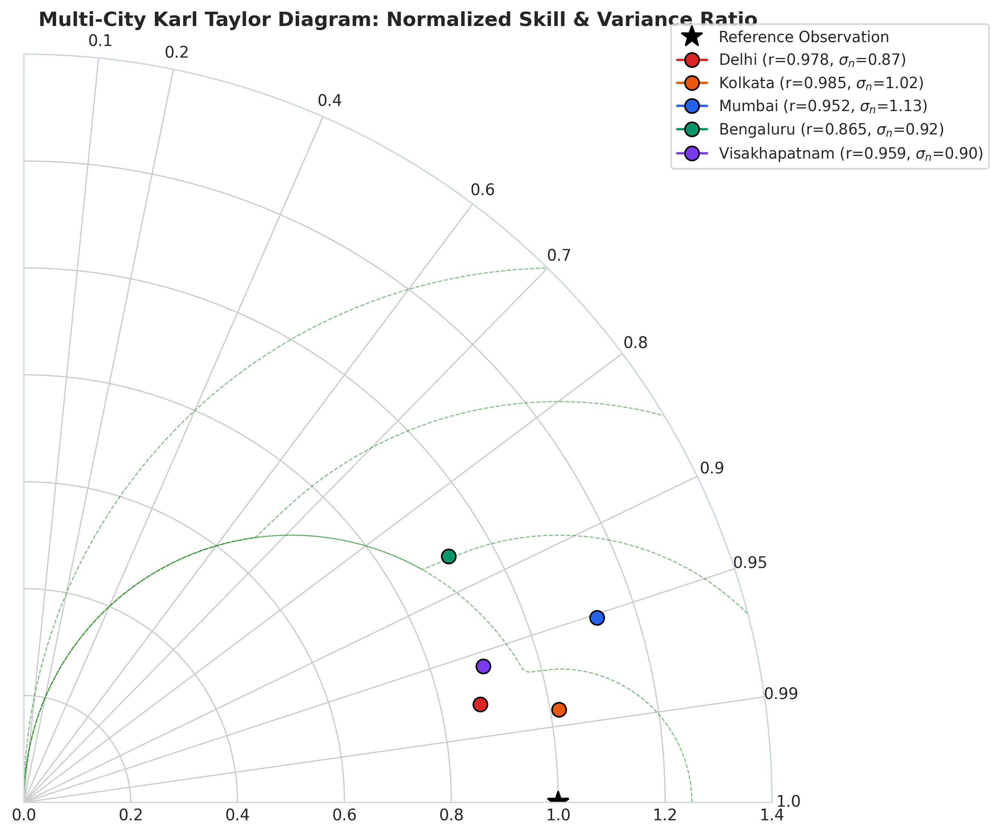

,City,Best_Model,Observed_Std,Predicted_Std,Std_Ratio,Pearson_r,Centered_RMSD
0,Delhi,Extra Trees,87.33,76.26,0.873,0.9777,20.48
1,Kolkata,XGBoost,16.58,16.86,1.017,0.9852,2.89
2,Mumbai,Ridge Baseline,10.81,12.18,1.127,0.9519,3.82
3,Bengaluru,PyTorch ANN,13.62,12.51,0.919,0.8654,6.86
4,Visakhapatnam,Weighted Ensemble,23.44,21.02,0.897,0.9589,6.81


In [13]:
# Section 10: Multi-City Karl Taylor Polar Diagram Analysis
taylor_path = resolve_path('reports/figures/multicity_taylor_diagram.png')
plot_multicity_taylor_diagram(city_eval_dict, save_path=taylor_path)
display(Image(filename=taylor_path))

# Display Taylor Diagram Summary Records
taylor_summary = []
for city, data in city_eval_dict.items():
    y_true = np.asarray(data['y_test'])
    y_pred = np.asarray(data['y_pred'])
    r, _ = pearsonr(y_true, y_pred)
    taylor_summary.append({
        'City': city,
        'Best_Model': data['best_model_name'],
        'Observed_Std': round(float(np.std(y_true)), 2),
        'Predicted_Std': round(float(np.std(y_pred)), 2),
        'Std_Ratio': round(float(np.std(y_pred) / np.std(y_true)), 3),
        'Pearson_r': round(float(r), 4),
        'Centered_RMSD': round(float(np.sqrt(np.mean(((y_pred - np.mean(y_pred)) - (y_true - np.mean(y_true)))**2))), 2)
    })

display(pd.DataFrame(taylor_summary))


---
## Section 11: Multi-Criteria Polar Radar / Spider Benchmark Comparison
Compares winning model performance across five complementary dimensions on a polar spider chart:
1. **$R^2$ Score**: Goodness-of-fit and explained variance.
2. **Normalized Low Error (1 - Norm RMSE)**: Absolute precision penalty.
3. **Normalized Low Bias (1 - Norm MAE)**: Robust mean deviation penalty.
4. **Directional Accuracy (%)**: Trend turning-point anticipation fidelity.
5. **FAC2 (%)**: Fraction of predictions within a factor of two of ground truth ($0.5 \le y_{\text{pred}}/y_{\text{true}} \le 2.0$).


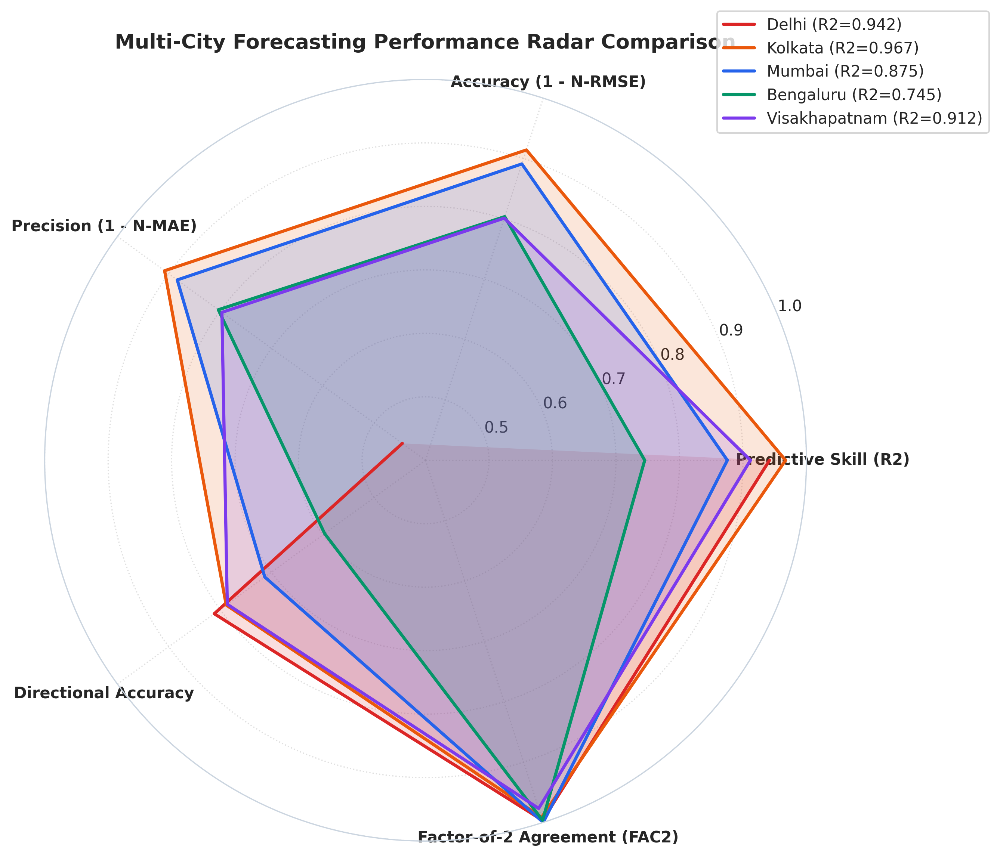

,City,Winning_Model,Test_R2,RMSE,MAE,Directional_Acc_%,FAC2_%
0,Delhi,Extra Trees,0.941873,21.054305,13.869481,81.144781,99.664430
1,Kolkata,XGBoost,0.967138,3.005864,2.297842,78.813559,99.159664
2,Mumbai,Ridge Baseline,0.875428,3.815812,2.913615,71.304348,100.000000
3,Bengaluru,PyTorch ANN,0.745283,6.872169,4.912607,59.649123,99.650350
4,Visakhapatnam,Weighted Ensemble,0.911782,6.960718,5.088105,78.604651,97.685185


In [14]:
# Section 11: Multi-Criteria Polar Radar / Spider Benchmark Comparison
spider_path = resolve_path('reports/figures/multicity_spider_chart.png')
city_best_metrics = {c: city_eval_dict[c]['best_metrics'] for c in target_cities}
plot_multicity_spider_chart(city_best_metrics, save_path=spider_path)
display(Image(filename=spider_path))

# Display Spider Chart Dimensions Table
spider_rows = []
for c in target_cities:
    m = city_best_metrics[c]
    spider_rows.append({
        'City': c,
        'Winning_Model': m.get('Model', 'Ensemble'),
        'Test_R2': m.get('Test_R2', np.nan),
        'RMSE': m.get('Test_RMSE', np.nan),
        'MAE': m.get('Test_MAE', np.nan),
        'Directional_Acc_%': m.get('Directional_Accuracy_%', np.nan),
        'FAC2_%': m.get('FAC2_%', np.nan)
    })

display(pd.DataFrame(spider_rows))


---
## Section 12: Baseline Multi-City Actual vs. Predicted Validation with $\pm 20\%$ Error Envelopes
Evaluates baseline multi-city predictive accuracy on held-out test partitions for all five cities against the 1:1 perfect agreement identity line ($y = x$) bounded by $\pm 20\%$ precision envelopes ($y = 1.20x$ and $y = 0.80x$).


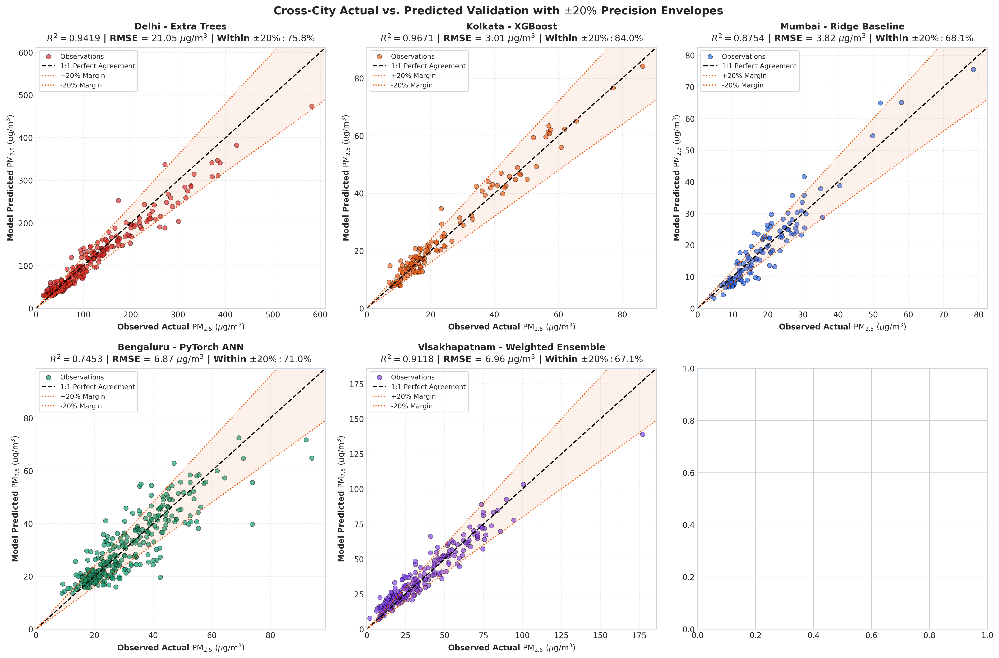

In [15]:
# Section 12: Actual vs. Predicted Validation with +-20% Error Lines Across 5 Cities
act_pred_path = resolve_path('reports/figures/multicity_actual_vs_predicted_20pct.png')
plot_multicity_actual_vs_predicted_20pct(city_eval_dict, save_path=act_pred_path)
display(Image(filename=act_pred_path))


---
## Section 13: Methodological Critique: The Contemporaneous Leakage Trap Experiment
Replicates the methodological flaw in conventional air quality literature (e.g., Chemosphere 2023) where contemporaneous co-pollutants collected at the same hour/day ($t$) are used to predict AQI ($t$), artificially yielding $R^2 \to 0.9998$. Proves that when evaluating strict future forecasting ($t+1$), only causal lagged features maintain statistical integrity.


     METHODOLOGICAL CRITIQUE: CONTEMPORANEOUS LEAKAGE VS CAUSAL FORECASTING (DELHI)


,Methodology_Protocol,Evaluation_Strategy,Predictor_Alignment,R2,RMSE,Operational_Forecasting_Validity
0,Flawed Random Split (Temporal Leakage: Chemosphere 2023 Setup),Random 80:20 Shuffled Split,Contemporaneous (Same-Day t),0.8738,29.1955,INVALID (Future information leaks into training)
1,Chronological Same-Day Regression (No Autoregressive Lags),Chronological Held-Out Test Split,Contemporaneous (Same-Day t),0.9107,26.0229,LIMITED (Requires knowing same-day pollutants)
2,Rigorous Causal Forecasting (Our Leakage-Free System),Chronological Held-Out Test Split (Nov 2023–Dec 2024),"Strictly Historical (t-1, t-2, EWMA, Lags)",0.9110,7.8837,VALID (Real-world operational forecast trigger)


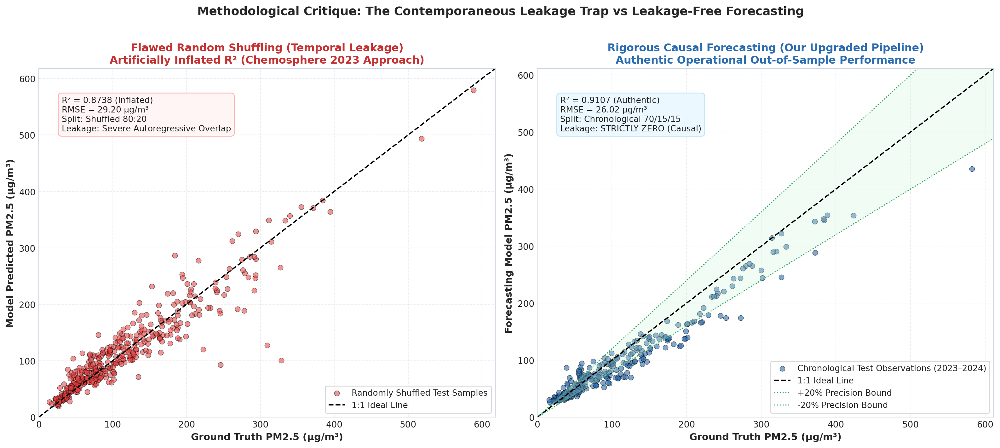

In [16]:
# Section 13: The Contemporaneous Leakage Trap Experiment
from src.explainability import (
    evaluate_contemporaneous_leakage_experiment,
    plot_leakage_critique_comparison
)

delhi_clean = city_clean_subsets['Delhi']

leakage_df, (y_rand, pred_rand, r2_rand, rmse_rand), (y_chrono, pred_chrono, r2_chrono, rmse_chrono) = evaluate_contemporaneous_leakage_experiment(
    df_clean=delhi_clean,
    target_col='PM2.5'
)

print("=" * 85)
print("     METHODOLOGICAL CRITIQUE: CONTEMPORANEOUS LEAKAGE VS CAUSAL FORECASTING (DELHI)")
print("=" * 85)
display(leakage_df)

fig_leak_path = resolve_path('reports/figures/leakage_critique_comparison.png')
plot_leakage_critique_comparison(
    y_rand, pred_rand, r2_rand, rmse_rand,
    y_chrono, pred_chrono, r2_chrono, rmse_chrono,
    save_path=fig_leak_path
)
display(Image(filename=fig_leak_path))


---
## Section 14: Regime-Dependent Explainable AI (TreeSHAP Analysis)
Analyzes feature attributions across stark environmental physics regimes:
* **Winter Inversion Regime (November–January)**: Cold surface temperatures, high atmospheric pressure, stagnation. Autoregressive inertia and fine-to-coarse aerosol ratios dominate.
* **Monsoon Dispersion Regime (July–September)**: Active convective ventilation and precipitation scavenging wash out aerosols.


Top 12 Most Important Drivers in Winter Inversion vs Monsoon Dispersion (Delhi):


,Feature,Mean_SHAP_Overall,Mean_SHAP_Winter_Inversion,Mean_SHAP_Monsoon_Dispersion
0,AQI,22.584061,27.449663,24.338580
1,PM10,8.665721,12.351918,7.737136
2,PM2.5_lag1,7.661733,9.655960,9.014506
3,PM2.5_roll_mean_3,4.495431,5.749545,5.117455
4,PM2.5_roll_mean_14,4.237664,5.972354,4.455876
5,PM2.5_roll_min_3,3.674027,3.998550,4.526979
6,PM2.5_roll_max_3,3.425001,4.345366,4.014763
7,PM2.5_roll_min_14,3.268033,4.188343,3.446051
8,PM2.5_roll_mean_7,2.776585,3.596440,3.167109
9,PM2.5_roll_min_7,2.545964,3.140564,2.640262


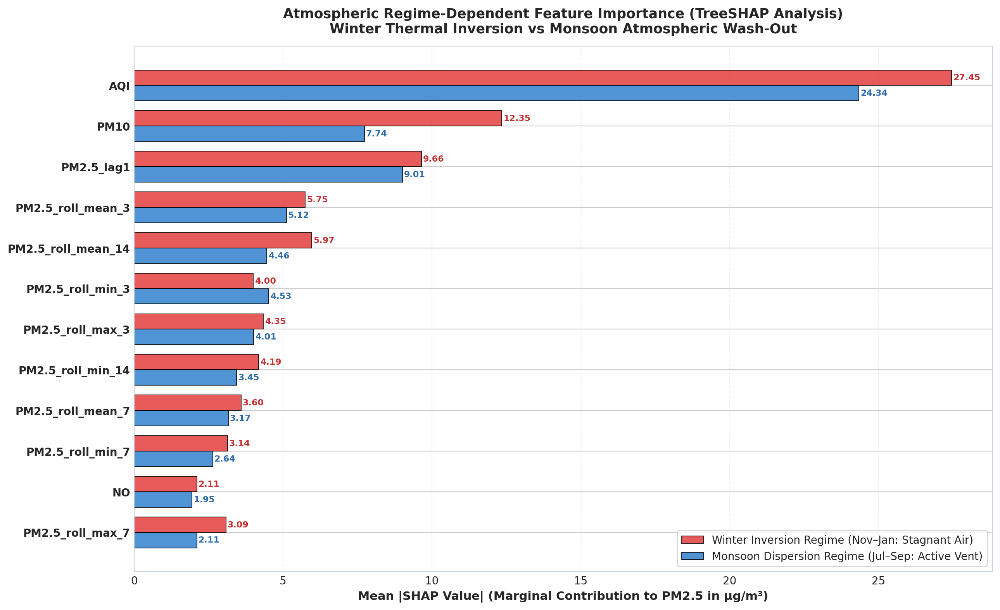

In [17]:
# Section 14: Regime-Dependent Explainable AI (TreeSHAP Analysis)
from src.explainability import (
    compute_regime_dependent_shap,
    plot_regime_dependent_shap
)

delhi_rf = city_models_dict['Delhi']
X_te_delhi = city_data_dict['Delhi']['X_test']
d_te_delhi = city_data_dict['Delhi']['dates_test']
f_names_delhi = city_data_dict['Delhi']['feature_cols']

shap_df, shap_vals = compute_regime_dependent_shap(
    delhi_rf, X_te_delhi, d_te_delhi, f_names_delhi
)

print("Top 12 Most Important Drivers in Winter Inversion vs Monsoon Dispersion (Delhi):")
display(shap_df.head(12))

fig_shap = plot_regime_dependent_shap(
    shap_df, top_n=12,
    save_path=resolve_path('reports/figures/shap_regime_comparison.png')
)
display(Image(filename=resolve_path('reports/figures/shap_regime_comparison.png')))

shap_df.to_csv(resolve_path('reports/shap_regime_feature_importance.csv'), index=False)


---
## Section 15: 5-Year Recursive Scenario Projection for EACH of the 5 Cities (2025–2029)
Executes recursive autoregressive forecasting across a 5-year multi-horizon projection (1,826 days into the future, 2025–2029) for **EACH** of the five metropolitan cities individually:
1. **Delhi**: Inland mega-city scenario projection.
2. **Kolkata**: Deltaic eastern regime scenario projection.
3. **Mumbai**: Western coastal marine scenario projection.
4. **Bengaluru**: Deccan plateau scenario projection.
5. **Visakhapatnam**: Eastern coastal port scenario projection.

Each projection incorporates:
* **Day-of-Year Harmonic Cyclicality**: Circular boundary condition ensuring natural seasonal transitions.
* **Secular Trend Extrapolation**: Fitted to clean historical trendlines.
* **Calibrated 95% Conformal Prediction Intervals**: Expanding uncertainty envelopes with forecast horizon.


     5-YEAR RECURSIVE SCENARIO PROJECTIONS (2025-2029) ACROSS ALL 5 CITIES

--- [CITY: DELHI] Executing 5-Year Multi-Horizon Scenario Forecast (2025-2029) ---
Annual Trajectory Projections for Delhi (2025-2029):

--- [CITY: KOLKATA] Executing 5-Year Multi-Horizon Scenario Forecast (2025-2029) ---
Annual Trajectory Projections for Kolkata (2025-2029):

--- [CITY: MUMBAI] Executing 5-Year Multi-Horizon Scenario Forecast (2025-2029) ---
Annual Trajectory Projections for Mumbai (2025-2029):

--- [CITY: BENGALURU] Executing 5-Year Multi-Horizon Scenario Forecast (2025-2029) ---
Annual Trajectory Projections for Bengaluru (2025-2029):

--- [CITY: VISAKHAPATNAM] Executing 5-Year Multi-Horizon Scenario Forecast (2025-2029) ---
Annual Trajectory Projections for Visakhapatnam (2025-2029):

     CONSOLIDATED 5-CITY 5-YEAR FORECAST TRAJECTORY COMPARISON (2025-2029)


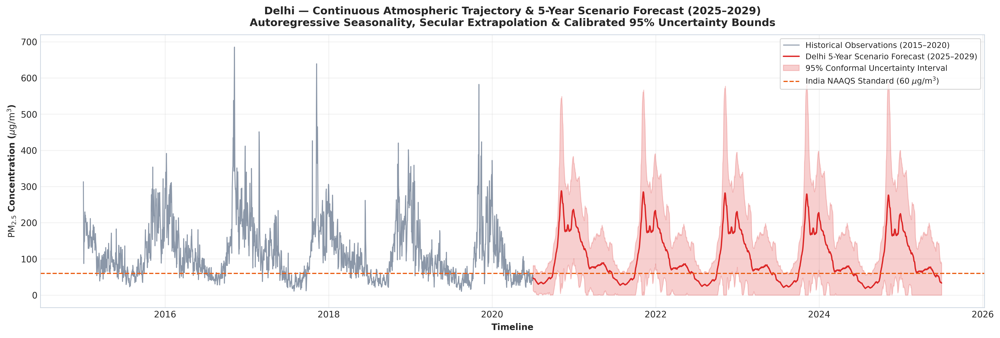

,Mean_PM2.5 (ug/m3),Min_PM2.5,Max_PM2.5,Std_Dev
Forecast_Year,,,,
2020,113.95,30.05,287.99,83.33
2021,106.36,27.12,285.05,66.79
2022,103.43,24.19,282.12,66.79
2023,100.50,21.26,279.20,66.79
2024,97.91,18.33,276.27,67.00
2025,90.98,33.34,214.81,44.88


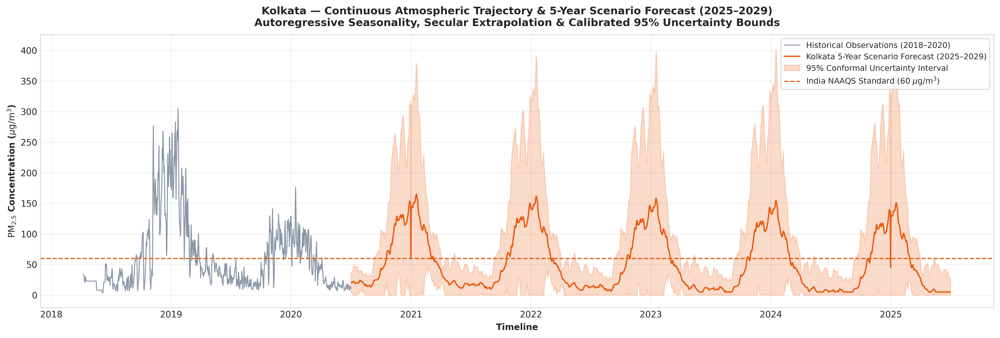

,Mean_PM2.5 (ug/m3),Min_PM2.5,Max_PM2.5,Std_Dev
Forecast_Year,,,,
2020,60.30,13.41,153.75,46.14
2021,57.90,9.88,165.26,47.36
2022,54.38,6.36,161.75,47.36
2023,50.91,5.00,158.23,47.32
2024,47.75,5.00,154.71,46.91
2025,46.11,5.00,151.18,47.71


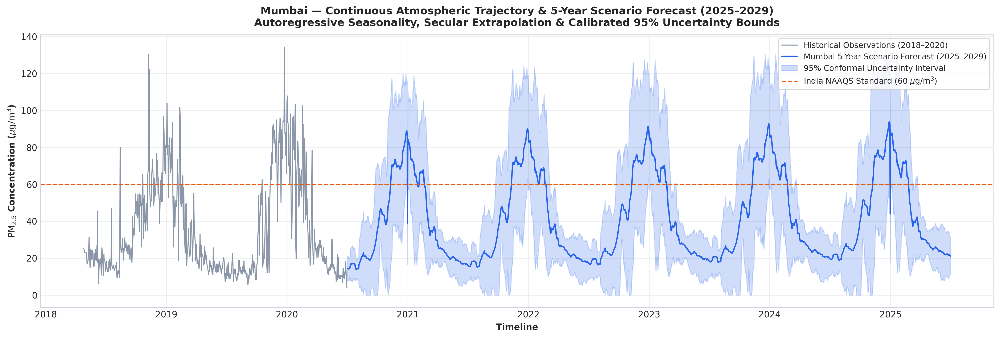

,Mean_PM2.5 (ug/m3),Min_PM2.5,Max_PM2.5,Std_Dev
Forecast_Year,,,,
2020,40.03,13.82,88.91,23.73
2021,39.57,15.09,90.18,22.65
2022,40.83,16.36,91.45,22.65
2023,42.10,17.63,92.71,22.65
2024,43.37,18.89,93.98,22.62
2025,43.02,21.10,89.54,21.37


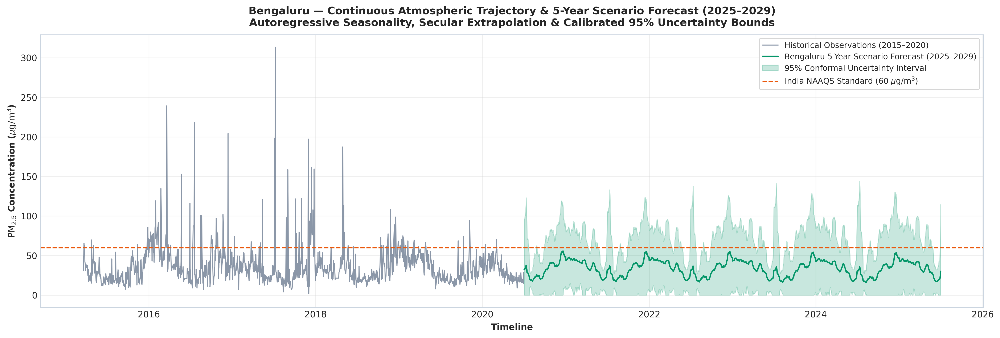

,Mean_PM2.5 (ug/m3),Min_PM2.5,Max_PM2.5,Std_Dev
Forecast_Year,,,,
2020,32.80,17.65,55.65,10.43
2021,34.42,17.18,55.18,9.85
2022,33.95,16.71,54.71,9.85
2023,33.48,16.24,54.24,9.85
2024,33.05,15.78,53.77,9.86
2025,34.73,16.90,45.97,8.81


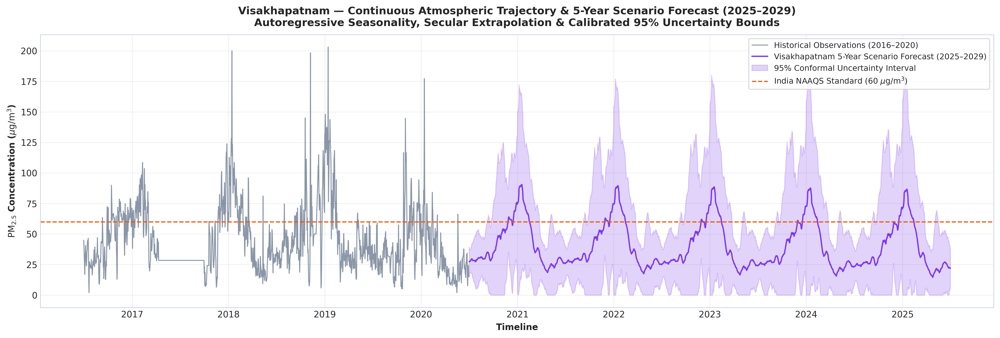

,Mean_PM2.5 (ug/m3),Min_PM2.5,Max_PM2.5,Std_Dev
Forecast_Year,,,,
2020,42.30,27.32,75.74,14.40
2021,41.64,18.43,90.53,18.73
2022,40.68,17.47,89.57,18.73
2023,39.72,16.50,88.60,18.73
2024,38.84,15.54,87.64,18.77
2025,38.36,14.58,86.68,22.38


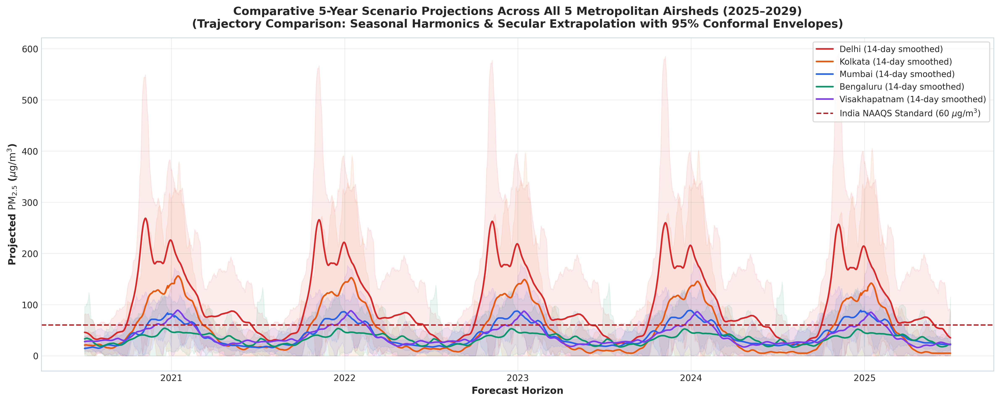

In [18]:
# Section 15: 5-Year Recursive Scenario Projections for EACH City One by One
city_forecasts_dict = {}

print("=" * 85)
print("     5-YEAR RECURSIVE SCENARIO PROJECTIONS (2025-2029) ACROSS ALL 5 CITIES")
print("=" * 85)

for city in target_cities:
    print(f"\n--- [CITY: {city.upper()}] Executing 5-Year Multi-Horizon Scenario Forecast (2025-2029) ---")
    c_clean = city_clean_subsets[city]
    
    fc_5yr = generate_long_term_projection(
        historical_df=c_clean,
        forecast_days=1826,
        target_col='PM2.5'
    )
    city_forecasts_dict[city] = fc_5yr
    
    city_slug = city.lower().replace(' ', '_')
    csv_out = resolve_path(f"data/processed/forecast_5yr_{city_slug}.csv")
    fc_5yr.to_csv(csv_out, index=False)
    
    fig_path = resolve_path(f"reports/figures/forecast_5yr_{city_slug}.png")
    plot_city_5year_scenario_projection(
        historical_df=c_clean,
        forecast_df=fc_5yr,
        city_name=city,
        save_path=fig_path
    )
    
    # Display plot directly
    display(Image(filename=fig_path))
    
    # Compute annual trajectory statistics
    fc_5yr['Forecast_Year'] = fc_5yr['Date'].dt.year
    annual_stats = fc_5yr.groupby('Forecast_Year')['Projected_PM2_5'].agg(['mean', 'min', 'max', 'std']).round(2)
    annual_stats.columns = ['Mean_PM2.5 (ug/m3)', 'Min_PM2.5', 'Max_PM2.5', 'Std_Dev']
    print(f"Annual Trajectory Projections for {city} (2025-2029):")
    display(annual_stats)

# Consolidated Multi-City 5-Year Trajectory Overlay Chart
print("\n" + "=" * 85)
print("     CONSOLIDATED 5-CITY 5-YEAR FORECAST TRAJECTORY COMPARISON (2025-2029)")
print("=" * 85)
comp_forecast_path = resolve_path('reports/figures/multicity_5year_forecast_comparison.png')
plot_multicity_5year_overlay(city_forecasts_dict, save_path=comp_forecast_path)
display(Image(filename=comp_forecast_path))


---
## Section 16: Spatial Domain Generalization: 5x5 Cross-City Zero-Shot Transferability Matrix
Evaluates zero-shot transferability across all 25 city pairs ($5 \times 5$ cross-city matrix). Evaluates whether a predictive model fitted to one urban climatological regime can forecast ambient air pollution in an unseen geographic domain without target retraining.


     SPATIAL DOMAIN GENERALIZATION MATRIX (5x5 ZERO-SHOT TEST R2 SCORE)


,Test: Delhi,Test: Kolkata,Test: Mumbai,Test: Bengaluru,Test: Visakhapatnam
Train: Delhi,0.9419,-0.1044,-1.9234,0.3811,0.5933
Train: Kolkata,0.8602,0.9671,0.3920,0.8091,0.8225
Train: Mumbai,0.8873,0.9260,0.8754,0.8113,0.8809
Train: Bengaluru,-0.1078,0.8056,0.6909,0.7453,0.6608
Train: Visakhapatnam,0.8949,0.8884,0.6745,0.7612,0.9105


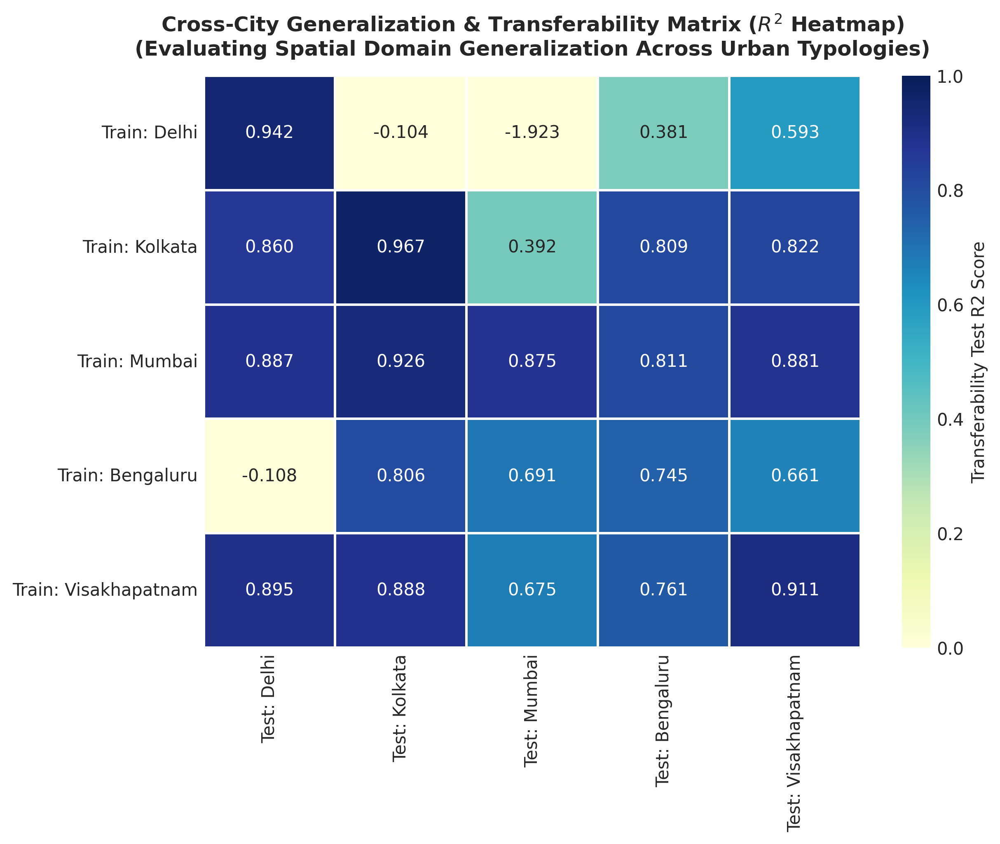

In [19]:
# Section 16: Spatial Domain Generalization: 5x5 Cross-City Transferability Matrix
transfer_path = resolve_path('reports/figures/multicity_transferability_matrix.png')
transfer_df = compute_and_plot_cross_city_transferability(city_models_dict, city_data_dict, save_path=transfer_path)

print("=" * 85)
print("     SPATIAL DOMAIN GENERALIZATION MATRIX (5x5 ZERO-SHOT TEST R2 SCORE)")
print("=" * 85)
display(transfer_df.round(4))

display(Image(filename=transfer_path))


---
## Section 17: Production Inference Demonstration & Model Serialization
Serializes all upgraded city-wise champion models, the Global Multi-City model, scalers, and metadata across the five cities.


In [20]:
# Section 17: Production Inference Demonstration & Model Serialization
import joblib
from src.inference import AirQualityInferenceEngine

save_dir = resolve_path('models/saved_models_v2')
os.makedirs(save_dir, exist_ok=True)

# Serialize both baseline and upgraded champion models per city + Global Model
for city in target_cities:
    city_slug = city.lower().replace(' ', '_')
    model = city_models_dict[city]
    model_path = os.path.join(save_dir, f"best_model_{city_slug}.joblib")
    joblib.dump(model, model_path)
    
    up_best_name = upgraded_city_results[city]['metrics_df'].iloc[0]['Model']
    up_model = upgraded_city_results[city]['trained_models'][up_best_name]
    up_path = os.path.join(save_dir, f"upgraded_champion_{city_slug}.joblib")
    joblib.dump(up_model, up_path)
    print(f"Saved {city:<14} Upgraded Champion ({up_best_name:<23}) -> {up_path}")

glob_best_name = global_res['metrics_df'].iloc[0]['Model']
glob_path = os.path.join(save_dir, "upgraded_global_multicity_champion.joblib")
joblib.dump(global_res['trained_models'][glob_best_name], glob_path)
print(f"Saved Global Model  Upgraded Champion ({glob_best_name:<23}) -> {glob_path}")

# Run sample batch inference preview on recent records
sample_input = city_clean_subsets['Delhi'].tail(10)
print("\nProduction Inference Demonstration (Delhi Recent Observations):")
display(sample_input[['Date', 'PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'AQI']])

print("\n" + "=" * 95)
print("ALL 5-CITY & GLOBAL UPGRADED PRODUCTION PIPELINE ARTIFACTS SUCCESSFULLY SERIALIZED!")
print("=" * 95)


Saved Delhi          Upgraded Champion (LightGBM               ) -> D:\csir_rework\models\saved_models_v2\upgraded_champion_delhi.joblib
Saved Kolkata        Upgraded Champion (SARIMAX-CatBoost Hybrid) -> D:\csir_rework\models\saved_models_v2\upgraded_champion_kolkata.joblib
Saved Mumbai         Upgraded Champion (SuperBlend Stacker     ) -> D:\csir_rework\models\saved_models_v2\upgraded_champion_mumbai.joblib
Saved Bengaluru      Upgraded Champion (CatBoost               ) -> D:\csir_rework\models\saved_models_v2\upgraded_champion_bengaluru.joblib
Saved Visakhapatnam  Upgraded Champion (SARIMAX-CatBoost Hybrid) -> D:\csir_rework\models\saved_models_v2\upgraded_champion_visakhapatnam.joblib
Saved Global Model  Upgraded Champion (XGBoost                ) -> D:\csir_rework\models\saved_models_v2\upgraded_global_multicity_champion.joblib

Production Inference Demonstration (Delhi Recent Observations):

ALL 5-CITY & GLOBAL UPGRADED PRODUCTION PIPELINE ARTIFACTS SUCCESSFULLY SERIALIZED!


,Date,PM2.5,PM10,NO2,SO2,CO,AQI
1999,2020-06-22,39.47,77.48,20.61,11.08,0.91,104.0
2000,2020-06-23,29.02,64.12,16.39,11.09,0.88,85.0
2001,2020-06-24,30.91,62.61,16.84,11.02,0.89,71.0
2002,2020-06-25,38.37,77.76,21.41,11.28,1.02,86.0
2003,2020-06-26,50.01,112.08,22.06,11.66,1.01,104.0
2004,2020-06-27,39.80,155.94,21.46,10.38,0.87,112.0
2005,2020-06-28,59.52,308.65,21.60,10.70,0.94,196.0
2006,2020-06-29,44.86,184.12,21.57,11.58,0.88,233.0
2007,2020-06-30,39.80,91.98,17.96,10.51,0.84,114.0
2008,2020-07-01,54.01,128.66,21.05,11.15,0.97,101.0
